# RL agent sims (260929): model characterisation by centrality strategy

Social (2-agent) self-play models trained in `Octagon/results/2609/260929`. This batch is the
first single-change arm after 260914 (`agent_training/READMEs/training_hyperparameters.md`).
260914 changed five settings from 260723 at once, and its peripheral group almost disappeared
(1 of 30 models, against 24 of 55 in 260723). 260929 keeps only the gamma change, and reverts
`lambd` and `time_horizon` to their 260723 values:

| setting | 260723 | 260914 | 260929 |
| --- | --- | --- | --- |
| extrinsic gamma | 0.99 | 0.998 | 0.998 |
| lambd | 0.95 | 0.99 | 0.95 |
| time_horizon | 128 | 512 | 128 |
| learning_rate / epsilon schedule | linear | constant | constant |
| max_steps | 4e6 | 7e6 | 7e6 |

Everything else is held at the 260914 values, including the build (`260914_01_social`), the trial
sequence (`trials_100000_seed17.json`) and the seeds. Model `NNNN` here trains on the same seed as
`260914_NNNN`, so the two batches pair model by model.

The penalty-break clause is out of this build, as for 260723 and 260914, so the resting metrics
are comparable across all three batches.

**The characterisation axis is centrality at slice onset.** For each trial, at the frame the
walls appear, centrality `= 1 - r/R` (1 = arena centre, 0 = alcove back). A model's mean over
trials is roughly where it stands when the trial starts.

**Plan**
1. **The strategy axis.** Per-model slice-onset centrality, and whether it splits into groups.
2. **Fingerprint by strategy.** Which metrics separate the groups, and which vary within them.
3. **Multivariate fingerprint.** Whether centrality is still the main axis once every metric is in.
4. **Seeds and the earlier batches.** Whether a seed keeps its strategy from 260914, how often seeds
   end up peripheral in each batch, and how the groups compare across 260723, 260914 and 260929.
5. **Model 32.** Whether the fastest peripheral model would hold up against central opponents.
6. **Sensing, loser's choice and the opponent.** What the agents sense, and whether they respond to
   where their opponent stands.

Stages 1-3 are the standard analysis. Stages 4 and 5 compare with the earlier batches and look at
model 32.

**Choices** (matching the earlier sim notebooks): FoV = 110.0; both agents pooled (self-play);
every number comes from `analysis/model_characterisation.py`. Metric definitions are in
`demos/strategy_characterisation/fingerprint_metrics.md`.

### Results:
Models 0001-0034, except 0027 (trained, not simulated): 33 models, 196-198 trials each.

- The strategy split is back. 27 models are central (onset centrality 0.732-0.937) and 6 are
  peripheral (0.002-0.065): 3, 15, 20, 23, 32 and 34. The gap between the groups is 0.667 wide,
  and the fixed cut and the GMM agree on every model
- Peripheral models wait inside the alcoves. Central models wait in a tight patch at the centre
- Central models choose High on almost every trial (`p_high` 0.998, lowest 0.955). Peripheral
  models choose it on 0.798
- Peripheral models stand still far more in the ITI (resting 0.390 against 0.017), travel less
  (13.5 against 43.8 units per ITI) and reach the wall slower (2.70 s against 2.01 s)
- Peripheral models start with a wall in view more often (0.843 against 0.691), but central
  models overtake them by 0.28 s. Peripheral models end 13.0% of trials without a wall ever in
  view, against 1.0%
- Peripheral models score less per second (`score_rate` 0.390 against 0.476). Model 32 is the
  exception, fast to the wall (1.88 s) with a score rate of 0.466
- Route directness does not separate the groups (`path_ratio` 1.151 against 1.174, eta² 0.02)
- PC1 of the fingerprint (centrality excluded) explains 55% and correlates +0.96 with centrality.
  Strategy is the main axis of this batch
- Within the central group, the widest spread is in standing still (`prop_no_translational`
  0.016-0.396) and in how fast a wall is seen. Models 21 and 9, the two least central, are also
  the slowest to see a wall and least direct
- Seeds do not keep their strategy. None of the 29 seeds shared with 260914 is peripheral in both
  batches
- 0.182 of models are peripheral, against 0.067 for 260914 (p = 0.26) and 0.473 for 260723
  (p = 0.0066). Gamma alone gives the 260914 central policy and removes most of the peripheral group
- Model 32 is a competent mover, but its self-play score rate owes much to self-play. Against
  central models it would win an estimated 0.367 of races, the best of the peripheral models but
  well short of even. The estimate uses each model's own `p_high`, and reproduces two past
  tournaments to within 0.031 on win share and 0.030 on score per trial
- Agents sense with 7 rays, not a continuous view, and the two seats sense each other differently. A
  loser's choice is called only when clear (32% of peripheral losers, 0.9986 correct on cut winners)
- In cross-model tournaments, seeing the opponent near High at slice onset does not change whether
  an agent heads for High (odds ratio 1.06, 95% interval 0.65-1.71, 94 exposed trials)

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import data_strings
import analysis.model_characterisation as mc
import data_extraction.data_saving as data_saving
import parse_data.identify_sim_filepaths as identify_sim_filepaths
import plotting.plot_octagon as plot_octagon

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)

# social self-play inference logs for this run live in a dated subfolder
BATCH = '260929'
SIM_DATA_FOLDER = os.path.join(data_strings.SIM_DATA_FOLDER, '2609', BATCH)

CURRENT_FOV = 110.0                 # agent camera FoV (total degrees)
RECOMPUTE = False                   # rebuild the cached long tables (loads every model's JSON)
LAST_MODEL = 34                     # the written results cover models up to here. Raise it as runs finish

## Models included

A simulation writes `DONE.txt` when it finishes. Only folders holding it are loaded, so a run still
being simulated is never read half-written. `LAST_MODEL` caps the list at the models the written
results cover, as more of the batch is still training. Trained models with no simulation folder
are listed too.

In [2]:
# find the simulated models, and keep those whose simulation finished
folders = dict(identify_sim_filepaths.get_model_folders(sim_data_folder=SIM_DATA_FOLDER))
done = {m: os.path.exists(os.path.join(SIM_DATA_FOLDER, f, 'DONE.txt')) for m, f in folders.items()}
ALL_MODELS = sorted(m for m, d in done.items() if d and m <= LAST_MODEL)

# find the trained models that have not been simulated yet
RESULTS_FOLDER = os.path.join(os.path.dirname(data_strings.SIM_DATA_FOLDER), 'results', '2609', BATCH)
trained = sorted(m for m, _ in identify_sim_filepaths.get_model_folders(sim_data_folder=RESULTS_FOLDER))

print(f"models simulated and finished: {len(ALL_MODELS)}")
print(ALL_MODELS)
print(f"simulation still running (no DONE.txt): {sorted(m for m, d in done.items() if not d)}")
print(f"finished but above LAST_MODEL: {sorted(m for m, d in done.items() if d and m > LAST_MODEL)}")
print(f"trained but not simulated: {sorted(set(trained) - set(folders))}")

models simulated and finished: 33
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 28, 29, 30, 31, 32, 33, 34]
simulation still running (no DONE.txt): []
finished but above LAST_MODEL: [35, 36, 37, 38, 39, 40, 41]
trained but not simulated: [27]


## Main pass over all models

One pass per model builds the long tables: `slice` (slice-onset centrality and x,z, one row per
trial x agent), `iti`, `vis`, `score`, `win` and `rt`. Each model is loaded, measured, then
discarded, so the batch stays memory-safe. The tables are cached, keyed on the model list, so a
new model being added triggers a rebuild.

In [3]:
# build the long tables, or load them if this model list is already cached
tables = data_saving.cached(f'model_characterisation_{BATCH}',
                            lambda: mc.collect_model_data(SIM_DATA_FOLDER, models=ALL_MODELS,
                                                          fov=CURRENT_FOV, verbose=False),
                            recompute=RECOMPUTE, stamp=tuple(ALL_MODELS))
USABLE_MODELS = mc.summarise_collection(tables, ALL_MODELS)
slice_df, iti_df = tables['slice'], tables['iti']

model_characterisation_260929: loaded from cache


usable models: 33 / 33
slice-onset rows: 13064 | ITIs: 13064 | visibility rows: 13064 | scored trials: 6532
trials per model: min 196, max 198


### Trial counts per model

Every model should contribute the same number of trials. One that contributes far fewer had its
simulation cut short, and its per-model means rest on less data.

In [4]:
# count the trials each model contributed, pooled over both agents
n_trials = (slice_df.groupby('model').size() // len(mc.PLAYERS)).rename('n_trials')
short = n_trials[n_trials < 0.9 * n_trials.median()]
print(f"trials per model: median {int(n_trials.median())}, min {int(n_trials.min())}, "
      f"max {int(n_trials.max())}")
print(f"models with a short run: {short.index.tolist() if len(short) else 'none'}")

trials per model: median 198, min 196, max 198
models with a short run: none


## Stage 1 - the strategy axis (centrality at slice onset)

**How to read the figures.** The first figure has one bar per model, ranked from lowest to highest
mean slice-onset centrality. Bar height is the model's mean over trials and both agents. The
whisker is the SD over those trials. The dotted line marks centrality 0.5, the fixed cut used
below. A centrality of 1 is the arena centre and 0 is the back of an alcove.

The second figure shows the same models in the same order, with each violin giving the spread of
single-trial centrality values. The red dot is the model mean.

**Why they are plotted.** The bars show whether the models spread smoothly along the axis or fall
into groups. The violins show whether a model starts every trial from about the same place, or
mixes positions from trial to trial.

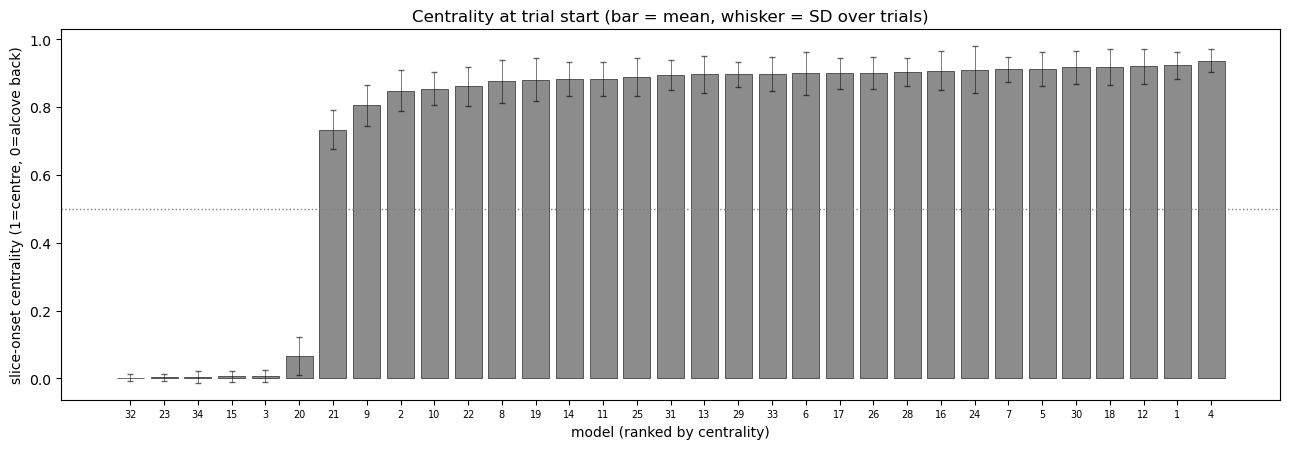

In [5]:
onset_by_model = mc.onset_centrality_by_model(slice_df)

# plot each model's mean onset centrality, ranked
order = onset_by_model.sort_values('onset_centrality').reset_index(drop=True)
x = np.arange(len(order))
fig, ax = plt.subplots(figsize=(13, 4.6))
ax.bar(x, order['onset_centrality'], yerr=order['onset_sd'], capsize=2,
       color='#8C8C8C', edgecolor='black', linewidth=0.4,
       error_kw=dict(lw=0.6, alpha=0.6))
ax.axhline(0.5, color='grey', ls=':', lw=1)
ax.set_xticks(x); ax.set_xticklabels(order['model'], fontsize=7)
ax.set_xlabel('model (ranked by centrality)'); ax.set_ylabel('slice-onset centrality (1=centre, 0=alcove back)')
ax.set_title('Centrality at trial start (bar = mean, whisker = SD over trials)')
plt.tight_layout(); plt.show()

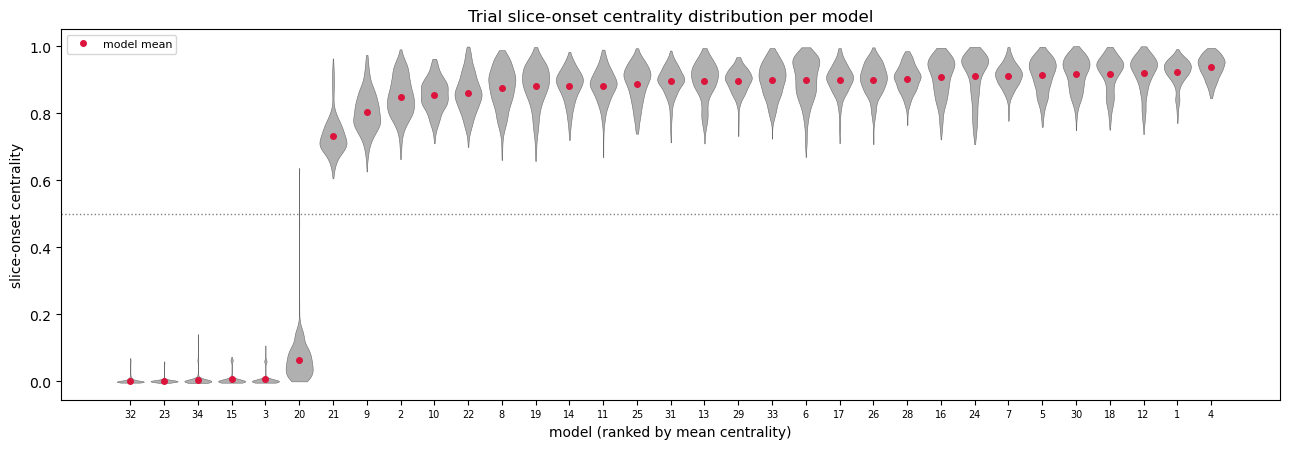

In [6]:
# plot the per-trial spread within each model, ordered by model mean
fig, ax = plt.subplots(figsize=(13, 4.6))
mean_order = onset_by_model.sort_values('onset_centrality')['model'].tolist()
sns.violinplot(data=slice_df, x='model', y='centrality', order=mean_order,
               density_norm='width', inner=None, cut=0, linewidth=0.4,
               color='#B0B0B0', ax=ax)
ax.plot(range(len(mean_order)),
        onset_by_model.set_index('model').loc[mean_order, 'onset_centrality'].values,
        'o', color='crimson', markersize=4, label='model mean')
ax.axhline(0.5, color='grey', ls=':', lw=1)
ax.set_xticks(range(len(mean_order)))
ax.set_xticklabels(mean_order, fontsize=7)
ax.set_xlabel('model (ranked by mean centrality)'); ax.set_ylabel('slice-onset centrality')
ax.set_title('Trial slice-onset centrality distribution per model')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

In [7]:
# take how far the lowest central model sits from the rest, and how wide the gap between groups is
s = onset_by_model.sort_values('onset_centrality')['onset_centrality'].to_numpy()
gaps = np.diff(s)
i = int(np.argmax(gaps))
print(f"largest gap between neighbouring models: {gaps[i]:.3f} (from {s[i]:.3f} to {s[i + 1]:.3f})")
print(f"models below the gap: {(s <= s[i]).sum()}, above: {(s > s[i]).sum()}")
print(f"spread above the gap: {s[i + 1]:.3f} to {s[-1]:.3f} (SD {s[i + 1:].std(ddof=1):.3f})")
print(f"spread below the gap: {s[0]:.3f} to {s[i]:.3f} (SD {s[:i + 1].std(ddof=1):.3f})")

largest gap between neighbouring models: 0.667 (from 0.065 to 0.732)
models below the gap: 6, above: 27
spread above the gap: 0.732 to 0.937 (SD 0.041)
spread below the gap: 0.002 to 0.065 (SD 0.025)


**Interpretation**

- The models fall into two groups with nothing between them. The largest gap between neighbouring
  models is 0.667 (from 0.065 to 0.732), with 6 models below it and 27 above.
- The upper group is tight (0.732-0.937, SD 0.041). The lower group sits at the alcove back
  (0.002-0.065, SD 0.025).
- Model 21 is the least central of the upper group, at 0.732. It is 0.073 below the next model
  (9, at 0.805), much smaller than the 0.667 gap to the lower group.

### Data-driven central vs peripheral split

The models are split two ways. (a) A fixed cut at centrality = 0.5. (b) A 2-component Gaussian
mixture (GMM) fit to the per-model means, which finds its own boundary. If the two agree and the
distribution has a clear gap, the split is real.

`split_strategies` also fits a 3-component mixture and, when it fits better by BIC, tags the
middle component `intermediate`. That label is printed but not used here (see below).

**How to read the figure.** One dot is one model, placed by its mean onset centrality. The vertical
position is random jitter, so the dots do not overlap, and means nothing. The grey curve is a
smoothed density of the model means. The dotted black line is the fixed cut at 0.5. The dashed red
line is the midpoint between the two GMM component means. Dot colour is the GMM label
(blue = central, orange = peripheral).

**Why it is plotted.** It shows whether the models form two separate groups, and whether the
two methods draw the boundary in the same gap.

GMM component means: [0.015 0.887]  weights: [0.82 0.18]
fixed(0.5) vs GMM agreement: 100%
strategy_gmm  strategy_fixed
central       central           27
peripheral    peripheral         6
Name: n, dtype: int64

3-component labels:
strategy
central         [1, 4, 5, 6, 7, 8, 11, 12, 13, 14, 16, 17, 18,...
intermediate                                       [2, 9, 10, 21]
peripheral                                [3, 15, 20, 23, 32, 34]


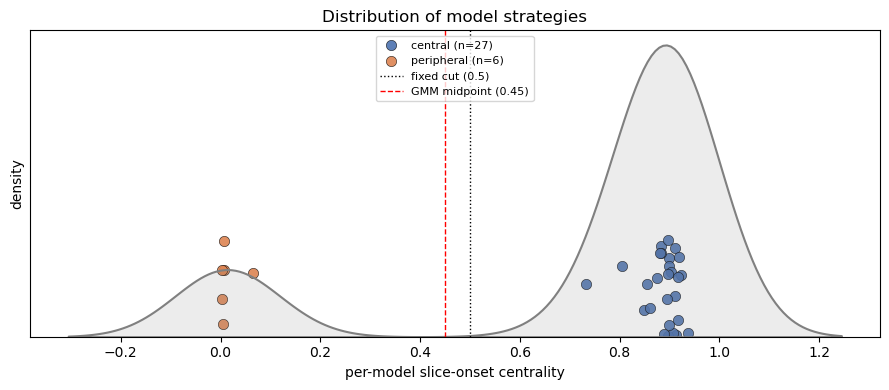

In [8]:
onset_by_model, gmm, boundary = mc.split_strategies(onset_by_model)
mc.report_strategy_split(onset_by_model, gmm)
print()
print("3-component labels:")
print(onset_by_model.groupby('strategy')['model'].apply(list).to_string())

# plot each model on the axis, coloured by the 2-component label
vals = onset_by_model['onset_centrality'].to_numpy()
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(9, 4))
for lab in mc.MAIN_STRATEGIES:
    sub = onset_by_model[onset_by_model['strategy_gmm'] == lab]
    ax.scatter(sub['onset_centrality'], rng.uniform(0, 1, len(sub)), color=mc.STRAT_PALETTE[lab],
               edgecolor='black', linewidth=0.4, s=55, alpha=0.9, label=f'{lab} (n={len(sub)})')
sns.kdeplot(x=vals, ax=ax, color='grey', lw=1.5, fill=True, alpha=0.15, bw_adjust=0.6)
ax.axvline(0.5, color='black', ls=':', lw=1, label='fixed cut (0.5)')
ax.axvline(boundary, color='red', ls='--', lw=1, label=f'GMM midpoint ({boundary:.2f})')
ax.set_yticks([]); ax.set_xlabel('per-model slice-onset centrality'); ax.set_ylabel('density')
ax.set_title('Distribution of model strategies')
ax.legend(fontsize=8, loc='upper center'); plt.tight_layout(); plt.show()

**Interpretation**

- The two methods agree on all 33 models. The GMM component means are 0.015 and 0.887, with
  weights 0.18 and 0.82.
- The 3-component fit tags models 2, 9, 10 and 21 as `intermediate`. These are the four least
  central models of the upper group (0.732-0.854). All four sit on the central side of the 0.667
  gap, so they are kept as central and the 2-component label is used.
- **Assumption to check:** treating 2, 9, 10 and 21 as central rather than as a third group.

In [9]:
# adopt the 2-component label as the working strategy
model_meta = mc.build_model_meta(USABLE_MODELS, onset_by_model, strategy_col='strategy_gmm')
mc.report_strategy_membership(model_meta)

CENTRAL = model_meta.loc[model_meta['strategy'] == 'central', 'model'].astype(int).tolist()
PERIPHERAL = model_meta.loc[model_meta['strategy'] == 'peripheral', 'model'].astype(int).tolist()

Strategy membership (working label = GMM):
  central     (n=27): [1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 16, 17, 18, 19, 21, 22, 24, 25, 26, 28, 29, 30, 31, 33]
  peripheral  (n= 6): [3, 15, 20, 23, 32, 34]
  intermediate (n= 0): []
  unassigned  (n= 0): []


## Stage 2 - the fingerprint by strategy

One row per model, with every metric in `mc.FP_METRICS`. In short (full definitions in
`fingerprint_metrics.md`):

| metric | what it measures |
| --- | --- |
| `onset_centrality` | mean centrality at slice onset |
| `iti_centrality` | mean centrality over the ITI frames |
| `prop_no_translational` | share of ITI frames with no translation (step < 0.05 units/frame) |
| `prop_no_rotational` | share of ITI frames with no rotation (< 0.5 deg/frame) |
| `proportion_resting` | share of ITI frames with neither (standing still and not turning) |
| `iti_path_len` | distance travelled per ITI (units) |
| `rot_total` | rotation per ITI (degrees) |
| `winner_path_len` | the winner's route length from slice onset to the trigger |
| `path_ratio` | that route over the straight-line distance (1 = perfectly direct) |
| `frac_visible_at_onset` | share of trials with a trial wall already in view at slice onset |
| `late_latency_to_wall_visible` | time to first see a wall, on trials where none was in view at onset (s) |
| `all_latency_to_wall_visible` | the same over every trial where a wall was seen, counting in-view-at-onset as 0 (s) |
| `latency_to_reach_wall` | median time from slice onset to the trigger (s) |
| `frac_never_visible` | share of trials that ended before a trial wall came into view |
| `frac_trials_over_5s` | share of trials slower than 5 s |
| `p_high` | share of trials won at the High wall |
| `mean_score` | agent 0's mean trial score (1.0 High, 0.4 Low, 0 lost) |
| `score_rate` | total score over total trial time (score per second) |

In [10]:
fingerprint = mc.build_fingerprint(model_meta, tables)
fingerprint[['model', 'strategy'] + mc.FP_METRICS].sort_values(['strategy', 'onset_centrality']).round(3)

,model,strategy,onset_centrality,iti_centrality,prop_no_translational,prop_no_rotational,proportion_resting,iti_path_len,rot_total,winner_path_len,path_ratio,frac_visible_at_onset,late_latency_to_wall_visible,all_latency_to_wall_visible,latency_to_reach_wall,frac_never_visible,frac_trials_over_5s,p_high,mean_score,score_rate
20,21,central,0.732,0.739,0.052,0.263,0.016,47.148,1321.145,25.179,1.384,0.625,1.606,0.424,2.026,0.151,0.061,1.000,0.423,0.391
8,9,central,0.805,0.820,0.016,0.487,0.010,48.705,918.491,21.772,1.220,0.611,0.930,0.338,1.964,0.040,0.005,1.000,0.535,0.452
1,2,central,0.848,0.819,0.025,0.249,0.010,48.316,1346.655,21.334,1.184,0.654,0.465,0.161,2.104,0.000,0.000,1.000,0.530,0.457
9,10,central,0.854,0.841,0.041,0.318,0.016,47.666,1223.510,20.477,1.167,0.702,0.316,0.094,1.936,0.000,0.000,1.000,0.490,0.488
21,22,central,0.860,0.884,0.041,0.303,0.019,47.381,1239.419,19.899,1.127,0.664,0.523,0.170,1.907,0.015,0.000,1.000,0.485,0.498
7,8,central,0.875,0.836,0.084,0.165,0.019,45.300,1504.273,20.255,1.128,0.652,0.242,0.085,2.037,0.000,0.000,1.000,0.480,0.487
18,19,central,0.881,0.869,0.072,0.065,0.010,45.853,1677.146,20.030,1.116,0.712,0.190,0.055,1.984,0.000,0.000,1.000,0.465,0.496
13,14,central,0.882,0.860,0.048,0.195,0.014,47.175,1445.655,20.634,1.144,0.694,0.218,0.067,2.084,0.000,0.000,1.000,0.535,0.473
10,11,central,0.883,0.870,0.016,0.281,0.008,48.594,1287.600,22.137,1.230,0.687,1.239,0.326,1.973,0.068,0.020,1.000,0.470,0.451
24,25,central,0.888,0.868,0.024,0.146,0.008,48.180,1536.401,19.580,1.105,0.664,0.190,0.064,1.957,0.000,0.000,1.000,0.520,0.501


### How much of each metric is strategy

For each metric, eta² is the share of the spread across models that lies between the two strategy
means (`SS_between / SS_total`). 1 means the metric is fully set by strategy. 0 means the two
groups have the same mean, and all the spread is within them.

This is descriptive. The labels come from onset centrality on the same data, so eta² is circular
for any metric that tracks centrality, and `p_anova` is not a valid test (see the `mc` docstring).
With only a handful of peripheral models, read the group means alongside the eta² ordering.

In [11]:
var_table = mc.between_strategy_variance(fingerprint)
print(f"central n={len(CENTRAL)}, peripheral n={len(PERIPHERAL)}")
var_table.round(3)

central n=27, peripheral n=6


,metric,eta2_between_strategy,p_anova,central_mean,peripheral_mean
1,iti_centrality,0.988,0.000,0.880,0.018
0,onset_centrality,0.988,0.000,0.887,0.015
15,p_high,0.919,0.000,0.998,0.798
5,iti_path_len,0.798,0.000,43.814,13.540
2,prop_no_translational,0.744,0.000,0.110,0.641
9,frac_visible_at_onset,0.729,0.000,0.691,0.843
4,proportion_resting,0.709,0.000,0.017,0.390
12,latency_to_reach_wall,0.656,0.000,2.011,2.700
13,frac_never_visible,0.642,0.000,0.010,0.130
17,score_rate,0.620,0.000,0.476,0.390


**How to read the figure.** One panel per metric. Each dot is one model, split into central (blue)
and peripheral (orange) and jittered sideways so the dots do not overlap. The black bar is the
group mean. The panel title gives the metric's eta² from the table above.

**Why it is plotted.** A mean can hide whether a group difference is every model shifting together
or one or two extreme models. With so few peripheral models, that matters for every metric.

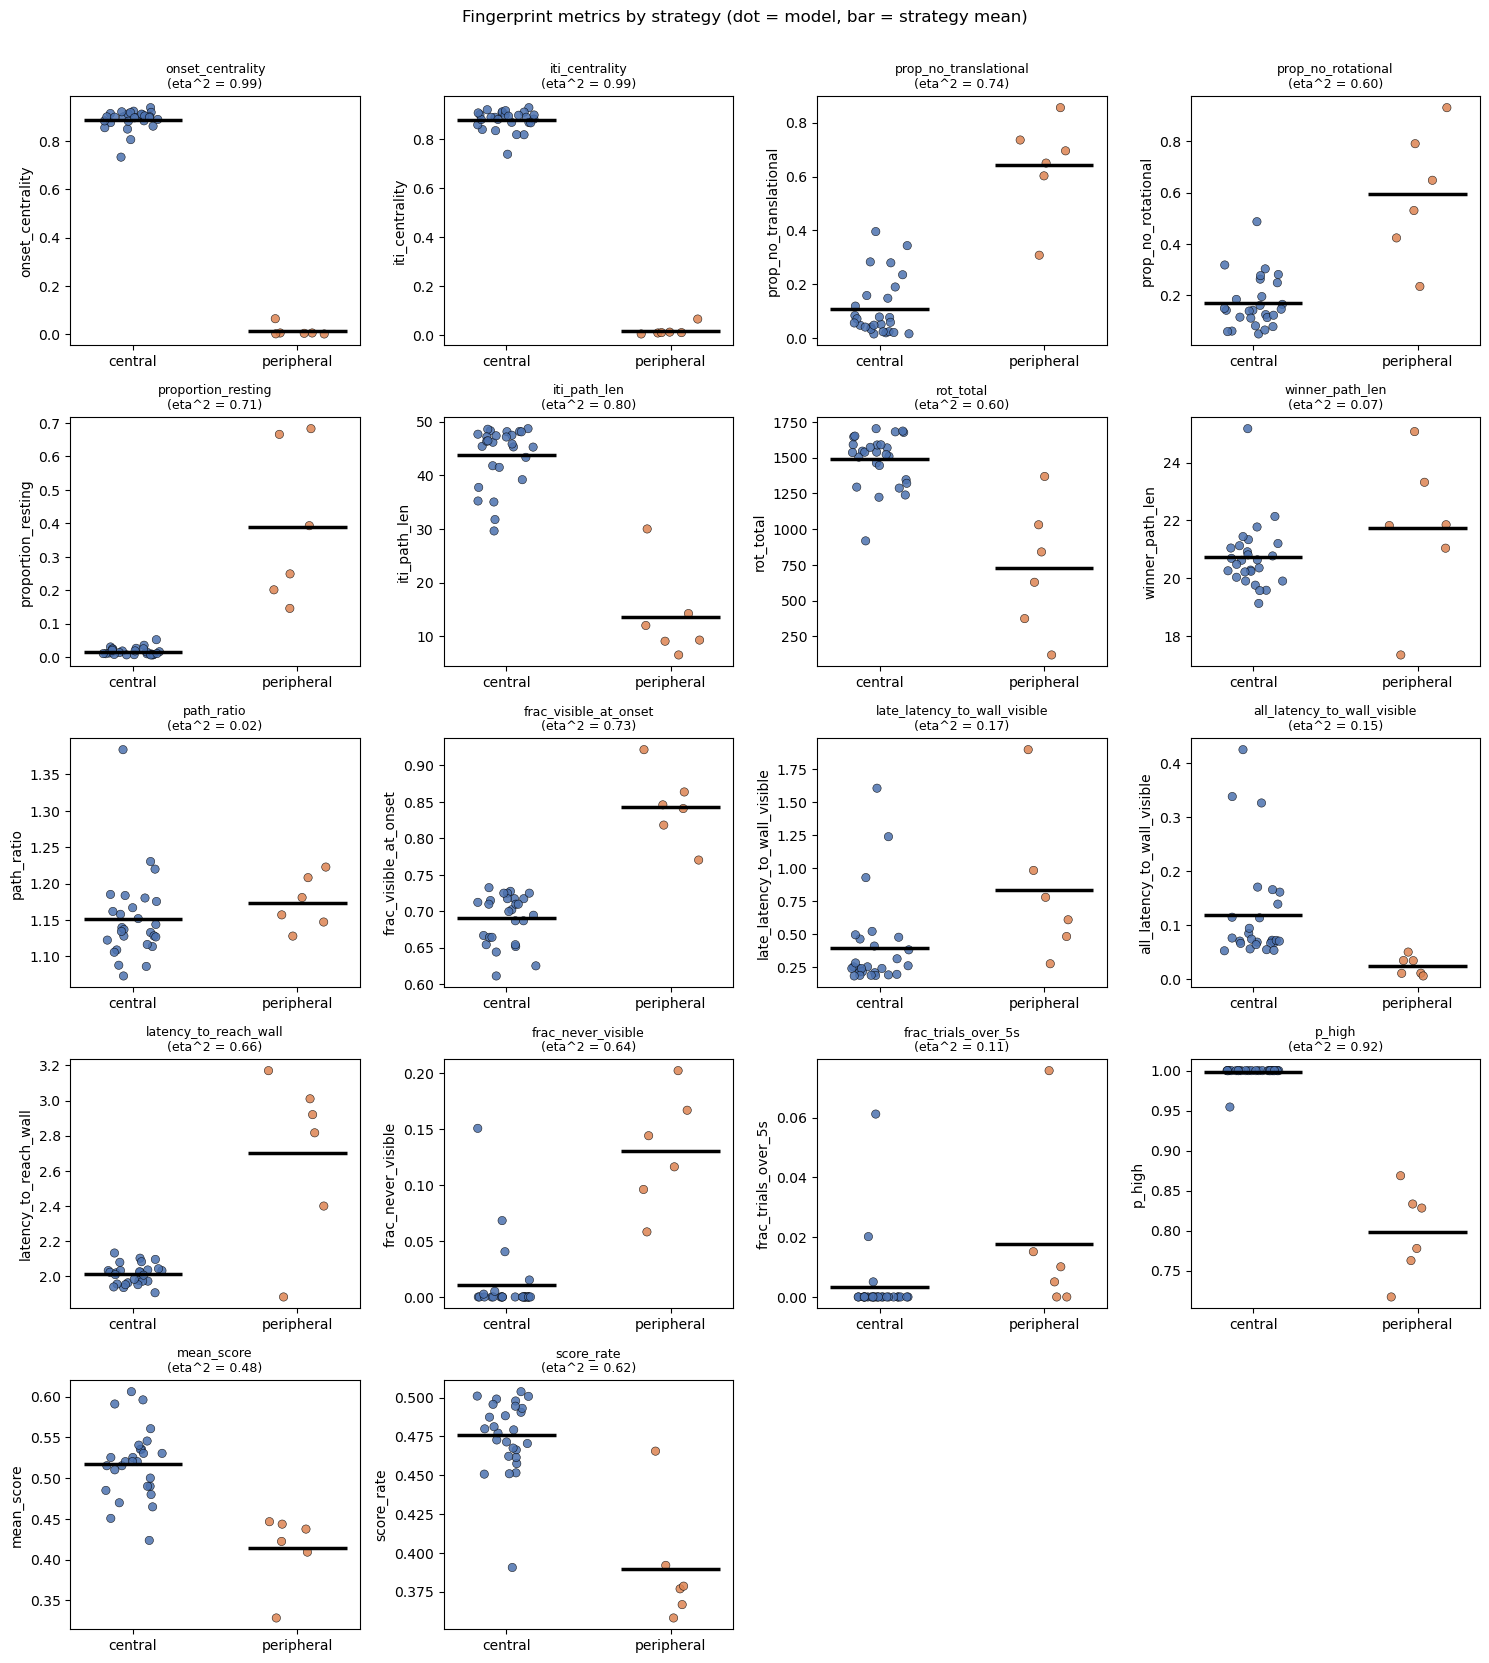

In [12]:
# plot central vs peripheral for each fingerprint metric (dot = model, bar = strategy mean)
ncol = 4
nrow = int(np.ceil(len(mc.FP_METRICS) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.3 * nrow))
eta = var_table.set_index('metric')['eta2_between_strategy']
for ax, m in zip(axes.ravel(), mc.FP_METRICS):
    sns.stripplot(data=fingerprint, x='strategy', y=m, order=list(mc.MAIN_STRATEGIES),
                  hue='strategy', palette=mc.STRAT_PALETTE, size=6, jitter=0.18,
                  alpha=0.85, edgecolor='black', linewidth=0.4, legend=False, ax=ax)
    means = fingerprint.groupby('strategy')[m].mean()
    for i, g in enumerate(mc.MAIN_STRATEGIES):
        ax.hlines(means[g], i - 0.3, i + 0.3, color='black', lw=2.5, zorder=5)
    ax.set_title(f'{m}\n(eta^2 = {eta[m]:.2f})', fontsize=9); ax.set_xlabel('')
for ax in axes.ravel()[len(mc.FP_METRICS):]:
    ax.axis('off')
plt.suptitle('Fingerprint metrics by strategy (dot = model, bar = strategy mean)', y=1.005)
plt.tight_layout(); plt.show()

### Is the score gap more than the High-wall gap?

In self-play both agents run the same policy, so each wins about half the trials. Terminal score is
1.0 for High, 0.4 for Low and 0 for a loss, so a model's mean score is predicted from `p_high` alone
by `0.5 * (0.4 + 0.6 * p_high)`, with nothing fitted. `residual` is the observed `mean_score` minus
that prediction. A residual near zero means the score follows from the wall choice.

In [13]:
# predict mean score from p_high alone, and compare by strategy
pred = fingerprint[['model', 'strategy', 'p_high', 'mean_score']].copy()
pred['predicted'] = 0.5 * (0.4 + 0.6 * pred['p_high'])
pred['residual'] = pred['mean_score'] - pred['predicted']
pred.groupby('strategy')[['p_high', 'mean_score', 'predicted', 'residual']].agg(['mean', 'min', 'max']).round(3)

p_high               mean_score               predicted               residual              
             mean    min    max       mean    min    max      mean    min    max     mean    min    max
strategy                                                                                               
central     0.998  0.955  1.000      0.518  0.423  0.606     0.499  0.486  0.500    0.018 -0.077  0.106
peripheral  0.798  0.717  0.869      0.414  0.328  0.446     0.439  0.415  0.461   -0.025 -0.087  0.010

**Interpretation**

- Five metrics have eta² of 0.7 or more beyond the two centrality columns. `p_high` (0.998 against
  0.798, eta² 0.92), `iti_path_len` (43.8 against 13.5), `prop_no_translational` (0.110 against
  0.641), `frac_visible_at_onset` (0.691 against 0.843) and `proportion_resting` (0.017 against
  0.390).
- Peripheral models are slower to the wall (median 2.70 s against 2.01 s, eta² 0.66) and score less
  per second (0.390 against 0.476, eta² 0.62).
- Route length and directness barely differ (`winner_path_len` eta² 0.07, `path_ratio` eta² 0.02).
  Once a peripheral model moves, it moves about as directly as a central one.
- The peripheral group is not uniform. Resting runs from 0.146 (model 32) to 0.683 (model 3).
  Model 32 is fastest to the wall of the whole batch (1.88 s) and its score rate (0.466) sits near
  the central median (0.479). Model 34 barely turns (`rot_total` 120 degrees per ITI, against a
  central mean of 1489).
- Mean score follows the wall choice. The residual from `0.5 * (0.4 + 0.6 * p_high)` averages
  +0.018 for central and -0.025 for peripheral, and every model lies within 0.11 of its
  prediction. The lower peripheral score is mostly the lower `p_high` (predicted 0.439 against
  0.499).

### Spread within the central group

With 27 central models, the spread inside the group can be ranked, as in the 260914 notebook.
`cv` is SD / |mean|, the scale-free measure of spread. It blows up wherever the mean sits near zero,
so read `frac_never_visible` and `frac_trials_over_5s` from their min and max instead. The
peripheral group is too small to rank this way, so its models are listed in full instead.

In [14]:
# summarise how far the central models spread on each metric, ranked by CV
fp_central = fingerprint[fingerprint['strategy'] == 'central']
spread = fp_central[mc.FP_METRICS].agg(['mean', 'median', 'std', 'min', 'max']).T
spread['cv'] = spread['std'] / spread['mean'].abs()
spread = spread.rename_axis('metric').reset_index().sort_values('cv', ascending=False)
print(f"spread across the {len(fp_central)} central models (ranked by CV)")
spread.round(3)

spread across the 27 central models (ranked by CV)


,metric,mean,median,std,min,max,cv
14,frac_trials_over_5s,0.003,0.000,0.012,0.000,0.061,3.826
13,frac_never_visible,0.010,0.000,0.032,0.000,0.151,3.044
2,prop_no_translational,0.110,0.059,0.108,0.016,0.396,0.986
10,late_latency_to_wall_visible,0.395,0.255,0.341,0.186,1.606,0.863
11,all_latency_to_wall_visible,0.118,0.072,0.096,0.053,0.424,0.812
4,proportion_resting,0.017,0.014,0.011,0.007,0.052,0.630
3,prop_no_rotational,0.170,0.142,0.101,0.050,0.487,0.592
5,iti_path_len,43.814,46.167,5.481,29.643,48.705,0.125
6,rot_total,1488.732,1538.964,181.075,918.491,1703.436,0.122
16,mean_score,0.518,0.520,0.042,0.423,0.606,0.082


In [15]:
# list the models at either end of the widest-spread metrics. Only metrics whose median sits
# clear of zero are ranked, as CV around a near-zero mean is not comparable
solid = [m for m in spread['metric'] if fp_central[m].median() > 0]
TOP_N = 4
for m in solid[:TOP_N]:
    s = fp_central.set_index('model')[m].sort_values(ascending=False)
    print(f"{m}  (median {s.median():.3f})")
    print(f"   highest: {', '.join(f'{int(i)}={v:.3f}' for i, v in s.head(3).items())}")
    print(f"   lowest : {', '.join(f'{int(i)}={v:.3f}' for i, v in s.tail(3).items())}")
    print()

prop_no_translational  (median 0.059)
   highest: 16=0.396, 6=0.344, 4=0.283
   lowest : 1=0.020, 9=0.016, 11=0.016

late_latency_to_wall_visible  (median 0.255)
   highest: 21=1.606, 11=1.239, 9=0.930
   lowest : 25=0.190, 19=0.190, 26=0.186

all_latency_to_wall_visible  (median 0.072)
   highest: 21=0.424, 9=0.338, 11=0.326
   lowest : 19=0.055, 33=0.053, 30=0.053

proportion_resting  (median 0.014)
   highest: 4=0.052, 12=0.036, 16=0.031
   lowest : 26=0.007, 31=0.007, 1=0.007



In [16]:
# show the peripheral models one by one, beside the central median
fp_periph = fingerprint[fingerprint['strategy'] == 'peripheral'].set_index('model')[mc.FP_METRICS].T
fp_periph.columns = [f'model {int(c)}' for c in fp_periph.columns]
fp_periph.insert(0, 'central median', fp_central[mc.FP_METRICS].median())
fp_periph.round(3)

,central median,model 3,model 15,model 20,model 23,model 32,model 34
onset_centrality,0.898,0.006,0.006,0.065,0.003,0.002,0.005
iti_centrality,0.891,0.011,0.009,0.065,0.004,0.008,0.009
prop_no_translational,0.059,0.856,0.736,0.308,0.650,0.603,0.696
prop_no_rotational,0.142,0.791,0.530,0.648,0.424,0.235,0.931
proportion_resting,0.014,0.683,0.393,0.201,0.249,0.146,0.666
iti_path_len,46.167,6.535,9.307,30.017,12.031,14.254,9.094
rot_total,1538.964,374.818,841.164,628.764,1031.000,1368.964,120.436
winner_path_len,20.619,21.038,21.822,25.077,23.321,17.338,21.851
path_ratio,1.137,1.157,1.208,1.223,1.181,1.128,1.147
frac_visible_at_onset,0.702,0.864,0.770,0.922,0.846,0.818,0.841


**Interpretation**

- Choice and speed are flat across the central group. `p_high` has median 1.000 (lowest 0.955),
  and `latency_to_reach_wall` runs 1.91-2.13 s (CV 0.028).
- Standing still is the widest spread of the metrics clear of zero. `prop_no_translational` runs
  0.016-0.396. Models 16 (0.396), 6 (0.344) and 4 (0.283) stand still most, and also travel least
  in the ITI (29.6, 31.8 and 35.2 units). Resting, which also needs no turning, stays low in every
  central model (at most 0.052).
- Visibility latency is the next widest. Models 21 (1.61 s), 11 (1.24 s) and 9 (0.93 s) take
  longest to see a wall when none is in view at onset, against a median of 0.26 s.
- In the peripheral group, resting splits into two pairs at the ends. Models 3 and 34 rest about
  two thirds of the ITI (0.683, 0.666), and models 20 and 32 about a fifth or less (0.201, 0.146).

### Where each strategy stands at slice onset

**How to read the figure.** Each panel is a top-down view of the arena, with the octagon outline in
white. Colour is the number of slice-onset positions in each bin (60 x 60 bins across the arena),
on a log scale (`log(1 + count)`), so bright = many trials start there. Both agents are pooled. The
left panel pools all central models and the right panel all peripheral models.

**Why it is plotted.** Centrality is a distance from the centre and says nothing about direction.
The map shows where around the arena each group waits, for example along walls or in alcoves.

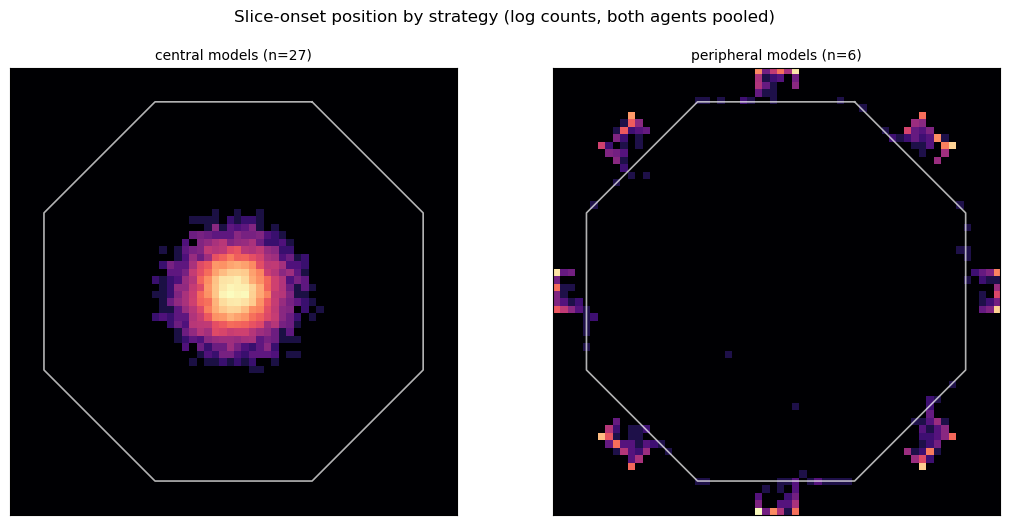

In [17]:
HIST_BINS = 60
R = mc.ARENA_RADIUS
extent = [-R, R, -R, R]
hrange = [[-R, R], [-R, R]]
slice_df['strategy'] = slice_df['model'].map(model_meta.set_index('model')['strategy'])

# plot the slice-onset occupancy of each strategy
oct_x, oct_y = plot_octagon.calculate_coordinates(vertex=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
for ax, lab in zip(axes, mc.MAIN_STRATEGIES):
    sub = slice_df[slice_df['strategy'] == lab]
    H, _, _ = np.histogram2d(sub['x'].to_numpy(float), sub['z'].to_numpy(float),
                             bins=HIST_BINS, range=hrange)
    ax.imshow(np.log1p(H).T, origin='lower', extent=extent, cmap='magma', aspect='equal')
    ax.plot(oct_x, oct_y, color='white', lw=1.2, alpha=0.7)
    ax.set_title(f'{lab} models (n={(model_meta.strategy == lab).sum()})', fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('Slice-onset position by strategy (log counts, both agents pooled)', y=1.0)
plt.tight_layout(); plt.show()

### When each strategy first sees a wall

**How to read the figure.** Top panel: the y-axis is the share of trials in which either trial wall
has entered the agent's FoV by the time on the x-axis (seconds from slice onset). Thin lines are
single models, bold lines the strategy mean (blue = central, orange = peripheral). The value at
t = 0 is `frac_visible_at_onset`. A trial that ends before a wall comes into view never counts as
seen, so each curve plateaus at `1 - frac_never_visible` rather than reaching 1.

Bottom panel: the share of trials still running at each time, per strategy mean. It shows how many
trials are left to contribute to the top curve.

**Why it is plotted.** Waiting position sets how often a wall is already in view when the trial
starts, and how long the agent has to turn before it sees one.

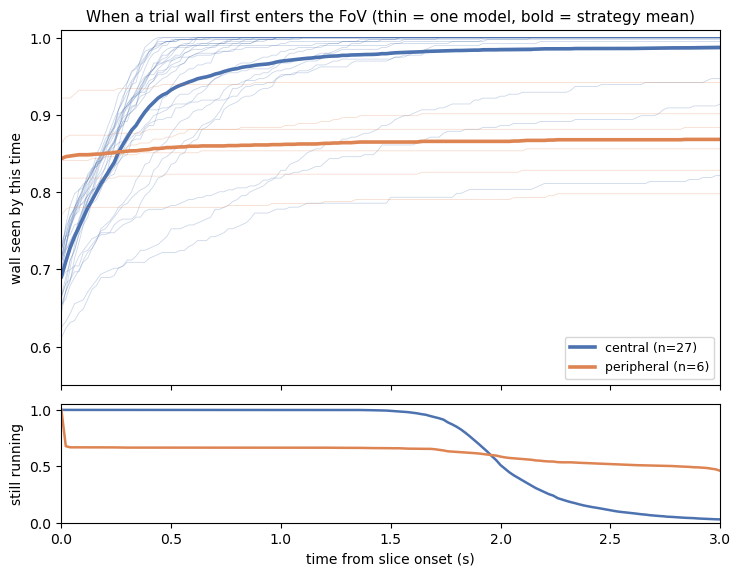

central curve overtakes peripheral at 0.28 s


,at_onset,at_3s
strategy,,
central,0.691,0.987
peripheral,0.843,0.868


In [18]:
# take the cumulative visibility curve for every model
curve = mc.wall_visible_curve(tables['vis'], model_meta, max_s=3.0)

fig, (ax, axr) = plt.subplots(2, 1, figsize=(8.5, 6.4), sharex=True,
                              gridspec_kw=dict(height_ratios=[3, 1], hspace=0.08))
for lab in mc.MAIN_STRATEGIES:
    sub = curve[curve['strategy'] == lab]
    # plot one thin line per model, so within-strategy spread stays visible
    for _, g in sub.groupby('model'):
        ax.plot(g['t'], g['p_visible'], color=mc.STRAT_PALETTE[lab], lw=0.6, alpha=0.28)
    # plot the strategy mean over the top
    m = sub.groupby('t')[['p_visible', 'p_running']].mean()
    ax.plot(m.index, m['p_visible'], color=mc.STRAT_PALETTE[lab], lw=2.6,
            label=f"{lab} (n={sub['model'].nunique()})")
    # plot how many trials are still going
    axr.plot(m.index, m['p_running'], color=mc.STRAT_PALETTE[lab], lw=1.8)

ax.set_ylim(0.55, 1.01); ax.set_ylabel('wall seen by this time')
ax.set_title('When a trial wall first enters the FoV (thin = one model, bold = strategy mean)',
             fontsize=11)
ax.legend(fontsize=9, loc='lower right')
axr.set_ylim(0, 1.05); axr.set_xlim(0, 3)
axr.set_ylabel('still running'); axr.set_xlabel('time from slice onset (s)')
plt.show()

# find the first time the central mean curve overtakes the peripheral one
means = curve.groupby(['strategy', 't'])['p_visible'].mean().unstack(0)
ahead = (means['central'] > means['peripheral']).to_numpy()
print(f"central curve overtakes peripheral at {means.index[np.argmax(ahead)]:.2f} s" if ahead.any()
      else "central curve never overtakes peripheral")

# print the values the curves start and end at
ends = curve.groupby(['strategy', 'model']).agg(at_onset=('p_visible', 'first'),
                                                 at_3s=('p_visible', 'last')).groupby('strategy').mean()
ends.round(3)

**Interpretation**

- Peripheral models start with a wall in view more often (0.843 against 0.691 at t = 0).
- The central mean curve overtakes the peripheral one at 0.28 s.
- By 3 s, 0.987 of central trials have had a wall in view, against 0.868 for peripheral. The
  peripheral curve stays flat because those trials end without the agent ever seeing a trial wall
  (`frac_never_visible` 0.130 against 0.010).

## Stage 3 - multivariate fingerprint

PCA of the standardised fingerprint, with the two centrality columns left out (`mc.PCA_METRICS`).
If PC1 still tracks centrality, the strategies differ in their movement, visibility and scoring
too, not only in where they stand.

**How to read the figure.** One dot is one model, placed by its scores on the first two principal
components. Each axis label gives the share of the total spread that component explains. Colour is
the strategy label, and numbers are model IDs. The loadings table below gives how strongly each
metric contributes to each component, and in which direction.

**Why it is plotted.** It tests whether the strategy split is one axis among several, or the main
thing that tells these models apart.

PC1 explains 55%, PC2 21% of fingerprint variance
corr(PC1, slice-onset centrality) = +0.96  (|r|~1 => centrality is the main axis; ~0 => something else is)


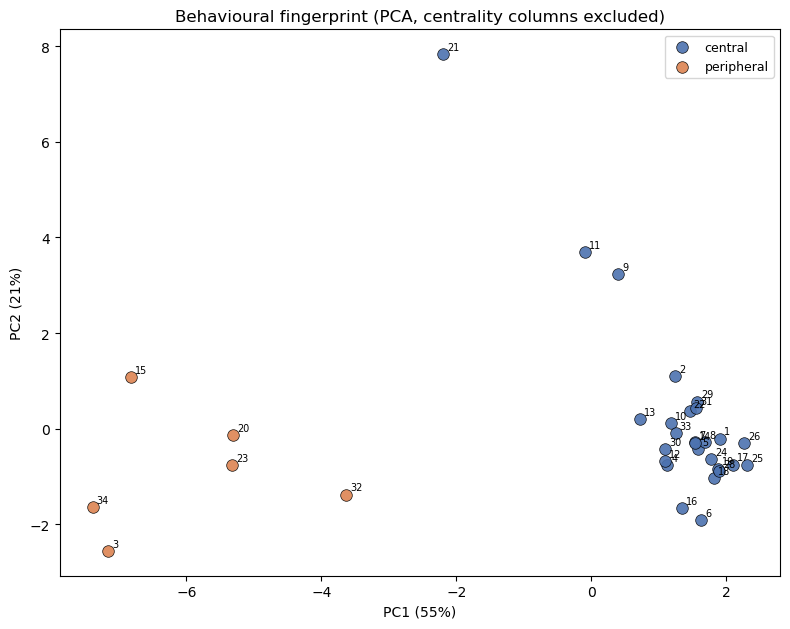

In [19]:
fingerprint, pca = mc.add_fingerprint_pca(fingerprint)
mc.report_pca(fingerprint, pca)

# plot every model on the first two components
fig, ax = plt.subplots(figsize=(8, 6.4))
for lab in mc.MAIN_STRATEGIES:
    sub = fingerprint[fingerprint['strategy'] == lab]
    ax.scatter(sub['pc1'], sub['pc2'], s=70, color=mc.STRAT_PALETTE[lab],
               edgecolor='black', linewidth=0.5, label=lab, alpha=0.9)
for _, r in fingerprint.iterrows():
    ax.annotate(int(r['model']), (r['pc1'], r['pc2']), fontsize=7, xytext=(3, 3),
                textcoords='offset points')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%})')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%})')
ax.set_title('Behavioural fingerprint (PCA, centrality columns excluded)')
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

In [20]:
# show which metrics load on each component, so the axes can be read
loadings = pd.DataFrame(pca.components_.T, index=mc.PCA_METRICS, columns=['pc1', 'pc2'])
loadings.reindex(loadings['pc1'].abs().sort_values(ascending=False).index).round(2)

,pc1,pc2
score_rate,0.30,-0.14
p_high,0.30,0.12
proportion_resting,-0.30,-0.15
frac_never_visible,-0.30,0.15
iti_path_len,0.29,0.21
rot_total,0.29,-0.01
prop_no_rotational,-0.29,0.01
prop_no_translational,-0.28,-0.21
latency_to_reach_wall,-0.28,-0.10
frac_visible_at_onset,-0.26,-0.26


In [21]:
# repeat the PCA on the central models only, to see what organises the group without the split
fp_c, pca_c = mc.add_fingerprint_pca(fingerprint[fingerprint['strategy'] == 'central'].drop(columns=['pc1', 'pc2']))
mc.report_pca(fp_c, pca_c)
pd.DataFrame(pca_c.components_.T, index=mc.PCA_METRICS, columns=['pc1', 'pc2']) \
    .sort_values('pc1', key=abs, ascending=False).round(2)

PC1 explains 48%, PC2 17% of fingerprint variance
corr(PC1, slice-onset centrality) = -0.86  (|r|~1 => centrality is the main axis; ~0 => something else is)


,pc1,pc2
all_latency_to_wall_visible,0.33,0.03
path_ratio,0.33,0.16
late_latency_to_wall_visible,0.33,0.10
frac_never_visible,0.32,0.17
winner_path_len,0.32,0.24
frac_trials_over_5s,0.30,0.23
score_rate,-0.29,-0.28
prop_no_rotational,0.25,-0.26
rot_total,-0.25,0.25
frac_visible_at_onset,-0.24,0.26


In [22]:
# check whether the central-only link to centrality rests on the two lowest central models
low = fp_c.nsmallest(2, 'onset_centrality')['model'].astype(int).tolist()
for drop in ([], low[:1], low):
    f, p = mc.add_fingerprint_pca(fp_c[~fp_c['model'].isin(drop)].drop(columns=['pc1', 'pc2']))
    r = np.corrcoef(f['pc1'], f['onset_centrality'])[0, 1]
    print(f"dropped {str(drop):9s} PC1 {p.explained_variance_ratio_[0]:.0%}  corr(PC1, centrality) = {r:+.2f}")

dropped []        PC1 48%  corr(PC1, centrality) = -0.86
dropped [21]      PC1 44%  corr(PC1, centrality) = -0.66
dropped [21, 9]   PC1 39%  corr(PC1, centrality) = -0.46


**Interpretation**

- Across the whole batch, PC1 explains 55% and correlates +0.96 with onset centrality, even with
  the centrality columns left out. The strategies differ on nearly everything at once.
- PC1 loads evenly (|0.23-0.30|) on scoring (`score_rate`, `p_high`), ITI movement and resting, and
  visibility (`frac_never_visible`, `frac_visible_at_onset`). PC2 (21%) loads on visibility latency
  (0.49) and route directness (0.47).
- Within the central group alone, PC1 explains 48% and loads on visibility latency, route length
  and directness, and `frac_never_visible` (0.32-0.33), against `score_rate` (-0.29). Its
  correlation with centrality is -0.86. That rests mostly on models 21 and 9. It falls to -0.66
  without model 21, and to -0.46 without both.
- So within the central group, a few models are slow to see a wall, take longer routes and score
  less per second. The two clearest of them are also the two least central.

## Stage 4 - seeds and the earlier batches

260929 differs from 260914 only in `lambd` and `time_horizon`, and from 260723 in gamma, the
schedules and `max_steps` (header table). Three questions.

1. **Does a seed keep its strategy across batches?** Model `NNNN` here trains on the same seed as
   `260914_NNNN`, so the two batches pair model by model for models 1-30. 260723 used seed 17 for
   every run, so it cannot be paired and enters as a group only.
2. **How often does a seed end up peripheral in each batch?**
3. **How do the central and peripheral groups compare across the three batches?**

All three batches are labelled by one rule here, so the counts compare like for like: a model is
**peripheral when its mean onset centrality is below 0.5**. Each batch's own GMM split is printed
alongside it. All three are finished policies (260723 at 4e6, the others at 7e6).

The 260723 tables are built once and cached (about 5 minutes for 55 models). The 260914 tables come
from the cache `human_agent_comparison` already keeps.

In [23]:
import analysis.human_agent_comparison as hac
from scipy import stats

CUT = 0.5                           # peripheral below this mean onset centrality, in every batch

# load the long tables of the two earlier batches
SIM_260914 = os.path.join(data_strings.SIM_DATA_FOLDER, '2609', '260914')
SIM_260723 = os.path.join(data_strings.SIM_DATA_FOLDER, '2607', '260723')
models_914, models_723 = mc.get_batch_models(SIM_260914), mc.get_batch_models(SIM_260723)
tables_914 = hac.load_agent_tables(SIM_260914, models_914, fov=CURRENT_FOV, recompute=RECOMPUTE)
tables_723 = data_saving.cached('model_characterisation_260723',
                                lambda: mc.collect_model_data(SIM_260723, models=models_723,
                                                              fov=CURRENT_FOV, verbose=False),
                                recompute=RECOMPUTE, stamp=tuple(models_723))


def batch_fingerprint(tables, batch):
    ''' Return one batch's fingerprint, labelled by the common cut and by its own GMM.
        Takes the batch's long tables and its name. '''

    onset, _, _ = mc.split_strategies(mc.onset_centrality_by_model(tables['slice']))
    meta = mc.build_model_meta(sorted(onset['model']), onset, strategy_col='strategy_gmm')
    fp = mc.build_fingerprint(meta, tables)
    fp['strategy'] = np.where(fp['onset_centrality'] < CUT, 'peripheral', 'central')
    return fp.assign(batch=batch)


fp_batches = {'260723': batch_fingerprint(tables_723, '260723'),
              '260914': batch_fingerprint(tables_914, '260914'),
              BATCH: batch_fingerprint(tables, BATCH)}
for b, f in fp_batches.items():
    print(f"{b}: {len(f)} models, peripheral by cut {(f.strategy == 'peripheral').sum()}, "
          f"by own GMM {(f.strategy_gmm == 'peripheral').sum()}")

agent_tables: loaded from cache
model_characterisation_260723: loaded from cache


260723: 55 models, peripheral by cut 26, by own GMM 24
260914: 30 models, peripheral by cut 2, by own GMM 3
260929: 33 models, peripheral by cut 6, by own GMM 6


### Does a seed keep its strategy?

**How to read the figure.** One dot is one seed, labelled with its model number. The x-axis is that
seed's mean onset centrality in 260914, the y-axis in 260929. Dotted lines mark the 0.5 cut on each
axis. A seed that kept its strategy sits in the top-right box (central in both) or the bottom-left
box (peripheral in both). Orange dots changed strategy between the batches.

**Why it is plotted.** If the seed decided the strategy, the 260914 off-cluster seeds would be the
ones that turned peripheral here, and the dots would lie along the diagonal.

seeds trained in both batches: 29
260929      central  peripheral
260914                         
central          23           4
peripheral        2           0

rank correlation of onset centrality across the pairs: +0.26 (p = 0.17)


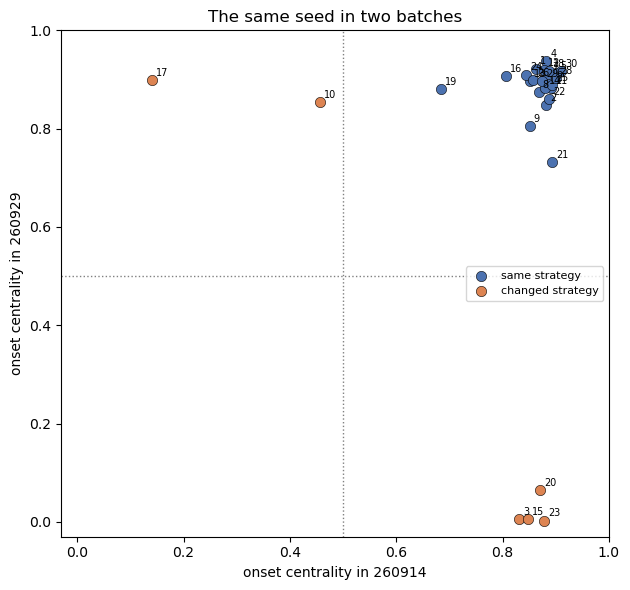

,onset_centrality_914,strategy_914,p_high_914,onset_centrality_929,strategy_929,p_high_929,changed
model,,,,,,,
3,0.831,central,1.000,0.006,peripheral,0.778,True
10,0.457,peripheral,0.742,0.854,central,1.000,True
15,0.847,central,1.000,0.006,peripheral,0.763,True
17,0.140,peripheral,0.965,0.899,central,1.000,True
20,0.870,central,1.000,0.065,peripheral,0.869,True
23,0.878,central,1.000,0.003,peripheral,0.833,True


In [24]:
# pair each seed's centrality across the two batches
paired = (fp_batches['260914'].set_index('model')[['onset_centrality', 'strategy', 'p_high']]
          .join(fp_batches[BATCH].set_index('model')[['onset_centrality', 'strategy', 'p_high']],
                lsuffix='_914', rsuffix='_929', how='inner'))
paired['changed'] = paired['strategy_914'] != paired['strategy_929']
print(f"seeds trained in both batches: {len(paired)}")
print(pd.crosstab(paired['strategy_914'], paired['strategy_929'],
                  rownames=['260914'], colnames=[BATCH]))
rho, p = stats.spearmanr(paired['onset_centrality_914'], paired['onset_centrality_929'])
print(f"\nrank correlation of onset centrality across the pairs: {rho:+.2f} (p = {p:.2f})")

# plot each seed's centrality in the two batches
fig, ax = plt.subplots(figsize=(6.4, 6))
for chg, col in ((False, '#4C72B0'), (True, '#DD8452')):
    sub = paired[paired['changed'] == chg]
    ax.scatter(sub['onset_centrality_914'], sub['onset_centrality_929'], s=55, color=col,
               edgecolor='black', linewidth=0.4, label='changed strategy' if chg else 'same strategy')
for m, r in paired.iterrows():
    ax.annotate(int(m), (r['onset_centrality_914'], r['onset_centrality_929']), fontsize=7,
                xytext=(3, 3), textcoords='offset points')
ax.axvline(CUT, color='grey', ls=':', lw=1); ax.axhline(CUT, color='grey', ls=':', lw=1)
ax.set_xlim(-0.03, 1); ax.set_ylim(-0.03, 1)
ax.set_xlabel('onset centrality in 260914'); ax.set_ylabel(f'onset centrality in {BATCH}')
ax.set_title('The same seed in two batches')
ax.legend(fontsize=8, loc='center right'); plt.tight_layout(); plt.show()

# list the seeds that changed
paired[paired['changed']].round(3)

**Interpretation**

- 29 seeds trained in both batches. Six of them are peripheral in one batch, and none is peripheral
  in both.
- 260914's two peripheral seeds are central here (model 10 0.457 -> 0.854, model 17 0.140 -> 0.899).
- The four paired seeds that are peripheral here (3, 15, 20, 23) were central in 260914, at
  0.831-0.878.
- Onset centrality barely carries over between the pairs (rank correlation +0.26, p = 0.17).
- So the seed does not set the strategy once `lambd` and `time_horizon` change. Pairing by seed
  helps nothing for this question, and the batches compare as groups.
- Whether the same seed with the same settings would repeat its strategy is not tested here.

### How often a seed ends up peripheral

`share` is the fraction of each batch's models below the cut. `ci_low` and `ci_high` are the exact
(Clopper-Pearson) 95% interval on that fraction, so they show how far the share could move with
a different draw of seeds. The second table gives Fisher's exact test on each pair of batches.

In [25]:
# count the peripheral models in each batch, with an exact interval on the share
rows = []
for b, f in fp_batches.items():
    k, n = int((f['strategy'] == 'peripheral').sum()), len(f)
    ci = stats.binomtest(k, n).proportion_ci(method='exact')
    rows.append(dict(batch=b, peripheral=k, models=n, share=k / n, ci_low=ci.low, ci_high=ci.high))
share = pd.DataFrame(rows).set_index('batch')
display(share.round(3))

# test each pair of batches for a difference in the peripheral share
tests = []
for a, b in ((BATCH, '260914'), (BATCH, '260723'), ('260914', '260723')):
    ka, na, kb, nb_ = share.loc[a, 'peripheral'], share.loc[a, 'models'], share.loc[b, 'peripheral'], share.loc[b, 'models']
    tests.append(dict(pair=f'{a} vs {b}', p_fisher=stats.fisher_exact([[ka, na - ka], [kb, nb_ - kb]])[1]))
pd.DataFrame(tests).round(4)

,peripheral,models,share,ci_low,ci_high
batch,,,,,
260723,26,55,0.473,0.337,0.612
260914,2,30,0.067,0.008,0.221
260929,6,33,0.182,0.070,0.355


,pair,p_fisher
0,260929 vs 260914,0.2609
1,260929 vs 260723,0.0066
2,260914 vs 260723,0.0001


**Interpretation**

- 6 of 33 260929 models are peripheral (0.182, interval 0.070-0.355). That sits between 260914
  (0.067, 0.008-0.221) and 260723 (0.473, 0.337-0.612).
- The share is clearly below 260723 (p = 0.0066), but cannot be told apart from 260914 (p = 0.26).
  The two intervals overlap from 0.070 to 0.221.
- Each batch's own GMM gives the same picture (24, 3 and 6 peripheral models).
- So the gamma change alone removes most of the 260723 peripheral group. Whether the `lambd` and
  `time_horizon` changes remove more cannot be settled with 33 models.

### The groups across the three batches

Group means of the main fingerprint metrics, for each strategy in each batch. `n` is the number of
models in the group. The 260914 peripheral group is two models (10 and 17), so read it as two
points, not a group. 260723 is at 4e6 steps and the other two at 7e6.

In [26]:
# compare group means across the batches
CMP = ['onset_centrality', 'p_high', 'proportion_resting', 'prop_no_translational', 'iti_path_len',
       'rot_total', 'frac_visible_at_onset', 'frac_never_visible', 'latency_to_reach_wall',
       'path_ratio', 'mean_score', 'score_rate']
all_fp = pd.concat(fp_batches.values(), ignore_index=True)
groups = all_fp.groupby(['strategy', 'batch'])[CMP].mean().T
groups.loc['n'] = all_fp.groupby(['strategy', 'batch']).size()
groups.round(3)

strategy                central                     peripheral                   
batch                    260723    260914    260929     260723    260914   260929
onset_centrality          0.835     0.867     0.887      0.088     0.298    0.015
p_high                    0.851     0.966     0.998      0.628     0.854    0.798
proportion_resting        0.027     0.051     0.017      0.102     0.009    0.390
prop_no_translational     0.126     0.182     0.110      0.242     0.099    0.641
iti_path_len             43.323    40.345    43.814     33.546    43.960   13.540
rot_total              1440.730  1379.113  1488.732   1076.272  1487.746  727.524
frac_visible_at_onset     0.685     0.682     0.691      0.764     0.696    0.843
frac_never_visible        0.000     0.003     0.010      0.108     0.038    0.130
latency_to_reach_wall     2.068     2.076     2.011      2.297     2.305    2.700
path_ratio                1.164     1.165     1.151      1.334     1.332    1.174
mean_score                0.458     0.499     0.518      0.389     0.439    0.414
score_rate                0.437     0.463     0.476      0.348     0.386    0.390
n                        29.000    28.000    27.000     26.000     2.000    6.000

**Interpretation**

- Central models reproduce 260914, and slightly exceed it. `p_high` goes 0.851 (260723), 0.966
  (260914), 0.998 (260929). `score_rate` goes 0.437, 0.463, 0.476. `latency_to_reach_wall` is
  2.068, 2.076, 2.011 and `path_ratio` 1.164, 1.165, 1.151.
- Central models rest least in 260929 (`proportion_resting` 0.017, against 0.027 and 0.051).
- The 260929 peripheral models are not like 260723's. They wait deeper in the alcoves (centrality
  0.015 against 0.088), rest far more (0.390 against 0.102), travel less in the ITI (13.5 against
  33.5 units) and turn less (728 against 1076 degrees).
- They also choose High more (0.798 against 0.628) and take more direct routes (`path_ratio` 1.174
  against 1.334), but are slower to the wall (2.700 s against 2.297 s). Score rates are close (0.390
  against 0.348).
- 260914's two peripheral models are not alcove-dwellers (mean centrality 0.298).

### Conclusion on the gamma-only arm

- **Gamma alone produces the 260914 central policy.** High preference, speed and route directness
  all match or beat 260914 with `lambd` and `time_horizon` back at their 260723 values.
- **Gamma alone removes most of the peripheral group** (0.473 -> 0.182). Whether the full
  credit-assignment package removes more (0.067) is not resolved at this sample size.
- **This is mostly what would be expected.** Gamma changes the objective, that is how far ahead a
  reward still counts. `lambd` and `time_horizon` change only how the advantage is estimated (its
  bias and variance), not what is being maximised. So gamma should carry most of the effect, and
  it does.
- A small extra peripheral share would also fit. With `lambd` 0.95 the advantage leans more on the
  value function. Credit for where to wait, which comes about 325 steps before the reward, then
  depends on a learned value of position. This is untested here.
- **Not expected:** the peripheral models that do appear rest and stand still far more than
  260723's. Nothing here explains it.
- **Caveats.** 260929 and 260723 still differ in the schedules and `max_steps`, as well as gamma.
  The 260929 training curves have not been checked for convergence. Models 0035 onward will narrow
  the peripheral-share interval.

## Stage 5 - model 32 against central opponents

Model 32 is the peripheral outlier. In self-play it reaches the wall fastest of the whole batch
(1.88 s) and its score rate (0.466) is close to the central median (0.479). The question is whether
that holds up against a central model, or only against a copy of itself.

In self-play both agents of a peripheral model wait in alcoves. Whichever happens to sit nearer a
lit wall wins, so the winner is the better placed of two peripheral agents. A central opponent
waits at the centre instead, about the same distance from every wall. So a self-play score is
measured against an opponent no central model resembles.

This stage first reads model 32's fingerprint, then estimates how it would race central models
from its own self-play data, after checking that estimate against two real tournaments.

### Model 32's fingerprint

`model 32` is its value. `central min`, `median` and `max` give the central group's range, and
`peripheral median` the median of the other five peripheral models. `rank in batch` ranks model 32
among all 33 models, 1 = highest value (so for `latency_to_reach_wall` rank 33 is the fastest).

In [27]:
# set model 32 beside the central range and the other peripheral models
FOCUS = 32
fp_i = fingerprint.set_index('model')
other_p = [m for m in PERIPHERAL if m != FOCUS]
card = pd.DataFrame({'model 32': fp_i.loc[FOCUS, mc.FP_METRICS],
                     'central min': fp_i.loc[CENTRAL, mc.FP_METRICS].min(),
                     'central median': fp_i.loc[CENTRAL, mc.FP_METRICS].median(),
                     'central max': fp_i.loc[CENTRAL, mc.FP_METRICS].max(),
                     'peripheral median': fp_i.loc[other_p, mc.FP_METRICS].median(),
                     'rank in batch': fp_i[mc.FP_METRICS].rank(ascending=False).loc[FOCUS]})
card.astype(float).round(3)

,model 32,central min,central median,central max,peripheral median,rank in batch
onset_centrality,0.002,0.732,0.898,0.937,0.006,33.0
iti_centrality,0.008,0.739,0.891,0.930,0.009,32.0
prop_no_translational,0.603,0.016,0.059,0.396,0.696,5.0
prop_no_rotational,0.235,0.050,0.142,0.487,0.648,13.0
proportion_resting,0.146,0.007,0.014,0.052,0.393,6.0
iti_path_len,14.254,29.643,46.167,48.705,9.307,29.0
rot_total,1368.964,918.491,1538.964,1703.436,628.764,21.0
winner_path_len,17.338,19.123,20.619,25.179,21.851,33.0
path_ratio,1.128,1.073,1.137,1.384,1.181,23.0
frac_visible_at_onset,0.818,0.611,0.702,0.732,0.846,5.0


In [28]:
# compare the two agents' win shares, as mean_score counts agent 0 only
sc = tables['score'][tables['score']['model'].isin(PERIPHERAL)]
agents = sc.groupby('model').agg(agent0_win=('score_p0', lambda s: (s > 0).mean()),
                                 agent1_win=('score_p1', lambda s: (s > 0).mean()), trials=('score_p0', 'size'))
agents['p_binom'] = [stats.binomtest(int(round(r.agent0_win * r.trials)), int(r.trials)).pvalue
                     for r in agents.itertuples()]
agents.round(3)

,agent0_win,agent1_win,trials,p_binom
model,,,,
3,0.510,0.490,198,0.831
15,0.470,0.530,198,0.434
20,0.480,0.520,198,0.619
23,0.465,0.535,198,0.356
32,0.404,0.596,198,0.008
34,0.480,0.520,198,0.619


**Interpretation**

- Model 32 is the fastest model to the wall in the batch (1.883 s, rank 33) and has the shortest
  winning route (17.3 units, rank 33). Its route is about as direct as a central model's
  (`path_ratio` 1.128, central median 1.137).
- It chooses High least of all 33 models (`p_high` 0.717).
- It is slow to find a wall when none is in view at onset (`late_latency_to_wall_visible` 1.898 s,
  the slowest). It ends 0.167 of trials without a trial wall ever in view (second highest).
- It is the most active peripheral model. It rests 0.146 of the ITI (peripheral median 0.393) and
  turns 1369 degrees per ITI, inside the central range (918-1703).
- Its `mean_score` (0.328) is the lowest in the batch, but this is a seat effect. `mean_score`
  counts agent 0 only, and model 32's agent 0 won 0.404 of trials against 0.596 for agent 1
  (p = 0.008). Its `score_rate` uses both agents.

### How model 32 wins in self-play

The race table holds one row per trial per agent: the agent's slice-onset position, its
straight-line distance to the centre of each lit wall's alcove (`d_high`, `d_low`), whether it won,
and the wall it reached. It is built from the logs once and cached.

As a check on the wall numbering, the winner's position at the trigger should sit nearest the alcove
of the wall the log says it triggered, on every trial.

In [29]:
import analysis.race_estimate as rc

# build the race table for the batch
race_df = data_saving.cached(f'race_table_{BATCH}',
                             lambda: rc.collect_race_table(SIM_DATA_FOLDER, ALL_MODELS, verbose=False),
                             recompute=RECOMPUTE, stamp=tuple(ALL_MODELS))
won = race_df[race_df['won']]
print(f"winner ends at the alcove of the wall it triggered: {(won['winner_end_wall'] == won['chosen_wall']).mean():.3f}")

# summarise how each peripheral model (and two central ones for reference) wins
OWN_ALCOVE = 3.0                    # units; an agent this close to a lit alcove centre is standing in it
rows = []
for m in PERIPHERAL + [1, 25]:
    w = won[won['model'] == m]
    rows.append(dict(model=m, strategy=fp_i.loc[m, 'strategy'],
                     wins_from_own_alcove=(w['d_chosen'] < OWN_ALCOVE).mean(),
                     winner_took_nearer_wall=(w['d_chosen'] <= w['d_nearest']).mean(),
                     p_high=w['chose_high'].mean(),
                     median_dist_winner=w['d_nearest'].median(),
                     median_dist_loser=race_df[(race_df['model'] == m) & ~race_df['won']]['d_nearest'].median()))
pd.DataFrame(rows).set_index('model').round(3)

race_table_260929: loaded from cache
winner ends at the alcove of the wall it triggered: 1.000


,strategy,wins_from_own_alcove,winner_took_nearer_wall,p_high,median_dist_winner,median_dist_loser
model,,,,,,
3,peripheral,0.323,0.677,0.778,16.186,16.235
15,peripheral,0.389,0.697,0.763,14.164,16.176
20,peripheral,0.227,0.601,0.869,15.382,15.386
23,peripheral,0.303,0.631,0.833,14.106,16.177
32,peripheral,0.434,0.808,0.717,13.143,16.136
34,peripheral,0.328,0.682,0.828,14.216,16.211
1,central,0.000,0.576,1.000,17.378,18.039
25,central,0.000,0.682,1.000,16.900,17.950


**Table columns.** `wins_from_own_alcove` is the share of won trials where the winner started
within 3 units of the wall it reached, so it was already standing in that alcove when the walls lit.
`winner_took_nearer_wall` is the share of wins at the nearer of the two lit walls. `p_high` is the
share of wins at High. `median_dist_winner` and `median_dist_loser` are the median distance from
each agent to its nearer lit wall at slice onset, for the winning and the losing agent.

**How to read the figure.** Distance at slice onset from an agent to its nearer lit wall (x-axis),
as a share of agent-trials (y-axis). Orange bars are model 32's winning agents, the orange line its
losing agents, and the blue line every agent of the central models. A peak near 0 is an agent
already standing in a lit alcove.

**Why it is plotted.** A central agent starts each trial at roughly one fixed distance from every
wall. Model 32's distance depends on which alcove it is in. The gap between its winners and losers
shows how much the self-play win owes to the better placed of its two agents.

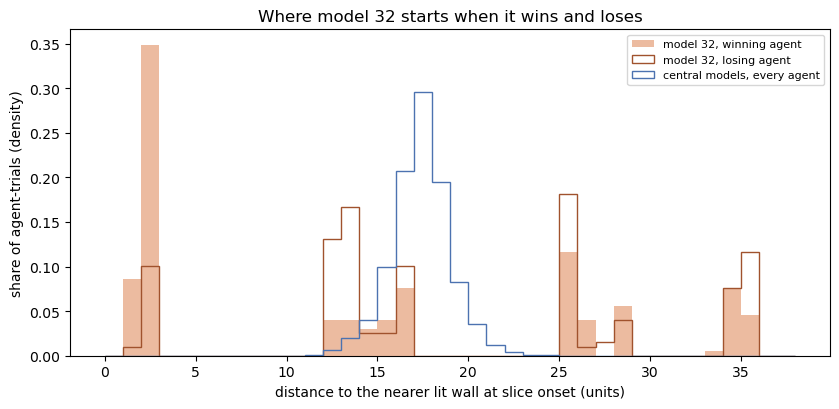

In [30]:
# plot the onset distance to the nearer lit wall for model 32's winners and losers, and central agents
r32 = race_df[race_df['model'] == FOCUS]
cen = race_df[race_df['model'].isin(CENTRAL)]
bins = np.linspace(0, 38, 39)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.hist(r32.loc[r32['won'], 'd_nearest'], bins=bins, density=True, color='#DD8452', alpha=0.55,
        label=f'model {FOCUS}, winning agent')
ax.hist(r32.loc[~r32['won'], 'd_nearest'], bins=bins, density=True, histtype='step', lw=2,
        color='#A0522D', label=f'model {FOCUS}, losing agent')
ax.hist(cen['d_nearest'], bins=bins, density=True, histtype='step', lw=2, color='#4C72B0',
        label='central models, every agent')
ax.set_xlabel('distance to the nearer lit wall at slice onset (units)')
ax.set_ylabel('share of agent-trials (density)')
ax.set_title(f'Where model {FOCUS} starts when it wins and loses')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Interpretation**

- 0.434 of model 32's wins start with the winner already standing in the lit alcove. That is the
  most of any peripheral model (others 0.227-0.389). Central models never do (0.000).
- Model 32 takes the nearer lit wall on 0.808 of its wins, also the most of the peripheral models.
- Its winning agent starts a median 13.1 units from the nearer lit wall, and its losing agent 16.1.
  A central agent starts about 17-18 units away.
- In the figure, model 32's distances fall at about 2, 13, 25 and 35 units, which are its own,
  the neighbouring, the next and the opposite alcove. The winners pile up at about 2 units.
- So model 32's self-play speed comes largely from trials where one of its two agents already
  stands in a lit alcove. Its 1.88 s is the faster of two agents spread over different alcoves.

### Is model 32 a good mover?

Trial time against the distance from the winner's onset position to the wall it reached, on won
trials. The slope is seconds per unit of distance, so a lower slope is a faster mover, and `r` is
how closely time follows distance. At the logged speed of 10 units/s a perfectly straight run would
have a slope of 0.1.

**How to read the figure.** One orange dot is one of model 32's won trials, and the orange line its
fit. Grey dots are the won trials of every central model, pooled, with the grey line their pooled
fit. Central models start close to the centre, so their distances span a narrow range.

**Why it is plotted.** If model 32 covers distance as quickly as central models, its movement is
sound and anything it lacks is in where it waits. The fits also feed the race estimate below.

,slope,intercept,r
median of,,,
central,0.136,-0.341,0.667
peripheral,0.123,-0.108,0.961


,slope,intercept,r,n
3,0.122,-0.105,0.976,198.0
15,0.133,-0.112,0.914,198.0
20,0.115,0.134,0.901,198.0
23,0.124,-0.054,0.981,198.0
32,0.121,-0.155,0.993,198.0
34,0.129,-0.114,0.945,198.0


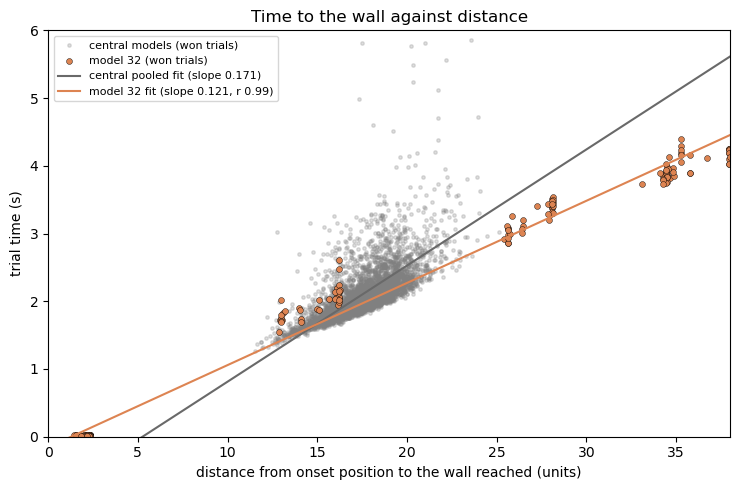

In [31]:
# fit time against distance for every model
fits = pd.DataFrame({m: rc.fit_time_distance(race_df[race_df['model'] == m]) for m in ALL_MODELS}).T
fits['strategy'] = fp_i['strategy']
display(fits.groupby('strategy')[['slope', 'intercept', 'r']].median().round(3).rename_axis('median of'))
display(fits.loc[PERIPHERAL, ['slope', 'intercept', 'r', 'n']].astype(float).round(3))

# plot model 32's time against distance beside the central models'
cw = cen[cen['won']]
pool = np.polyfit(cw['d_chosen'], cw['rt_s'], 1)
w32 = r32[r32['won']]
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(cw['d_chosen'], cw['rt_s'], s=6, color='grey', alpha=0.25, label='central models (won trials)')
ax.scatter(w32['d_chosen'], w32['rt_s'], s=18, color='#DD8452', edgecolor='black', linewidth=0.3,
           label=f'model {FOCUS} (won trials)')
xs = np.linspace(0, 38, 50)
ax.plot(xs, np.polyval(pool, xs), color='dimgrey', lw=1.5, label=f'central pooled fit (slope {pool[0]:.3f})')
f32 = fits.loc[FOCUS]
ax.plot(xs, f32['intercept'] + f32['slope'] * xs, color='#DD8452', lw=1.5,
        label=f"model {FOCUS} fit (slope {f32['slope']:.3f}, r {f32['r']:.2f})")
ax.set_xlim(0, 38); ax.set_ylim(0, 6)
ax.set_xlabel('distance from onset position to the wall reached (units)')
ax.set_ylabel('trial time (s)')
ax.set_title('Time to the wall against distance')
ax.legend(fontsize=8, loc='upper left'); plt.tight_layout(); plt.show()

**Interpretation**

- Model 32's trial time follows distance most tightly of any model (r = 0.993). Its slope is 0.121 s
  per unit, against 0.115-0.133 for the other peripheral models and a central median of 0.136.
- Central fits are looser (median r 0.667) because central distances span a narrow range.
- So model 32 is a competent mover. Once it sets off it covers ground as fast as any model here,
  and its self-play speed is not down to better movement than the others.

### Estimating a race against a different model

`analysis/race_estimate.py` estimates how model F would fare against model O from their self-play
logs alone:

1. For every agent and trial, pick the wall it heads for. It goes to High with the model's own
   self-play `p_high` and to Low otherwise, drawn at random for each agent and trial.
2. Predict its time to that wall from the model's own time-distance fit. This covers the losing
   agent too, whose time the log never records.
3. Add a timing residual drawn from that model's own won trials, so the trial-to-trial spread in
   timing is kept.
4. Pair every predicted F time with every predicted O time. The faster side wins and scores 1.0 at
   High or 0.4 at Low.

Two other wall rules are run for comparison. `high` sends every agent to High. `nearest` sends
every agent to the nearer of the two lit walls.

**Assumptions to check.**
- Neither model changes its behaviour because the opponent is different.
- The two agents never block each other, as each is timed alone.
- The wall choice is drawn independently of where the agent stands. `p_high` is the share of
  the model's self-play wins taken at High.
- Each fit uses won trials only, where a model may have moved better than on average.

**The check.** The 260715 tournament (8 models, three of them alcove-dwellers) and the 260914
tournament (5 models, including off-cluster model 260914_0017) both have self-play logs for every
entrant. Each ordered pair gives a real win share and score per trial to set against the
estimate. 260723's entrants
raced at 4e6, so their 4e6 self-play logs are used.

In [32]:
import analysis.tournament_analysis as ta

SIM = data_strings.SIM_DATA_FOLDER
# point each tournament entrant at the self-play logs of the same policy
ENTRANT_SIMS = {('260715', m): os.path.join(SIM, '2607', '260715') for m in (2, 10, 14, 15, 20, 22, 26, 36)}
ENTRANT_SIMS.update({('260914', m): os.path.join(SIM, '2609', '260914') for m in (14, 17, 20)})
ENTRANT_SIMS.update({('260723', m): os.path.join(SIM, 'stepmatch_4e6', '260723') for m in (34, 39)})
TOURNAMENTS = {'260715': os.path.join(SIM, 'tournaments', '260715'),
               '260914_vs_260723': os.path.join(SIM, 'tournaments', '260914_vs_260723_final')}
# label each entrant by strategy, as in the two tournament notebooks
ENTRANT_STRATEGY = {('260715', m): 'central' for m in (2, 20, 22)}
ENTRANT_STRATEGY.update({('260715', m): 'intermediate' for m in (10, 14)})
ENTRANT_STRATEGY.update({('260715', m): 'peripheral' for m in (15, 26, 36)})
ENTRANT_STRATEGY.update({('260914', 14): 'central', ('260914', 20): 'central', ('260914', 17): 'peripheral',
                         ('260723', 34): 'central', ('260723', 39): 'central'})

# build the entrants' race tables and load the tournaments, once each
race_entrants = data_saving.cached(
    'race_tables_tournament_entrants',
    lambda: pd.concat([rc.collect_race_table(f, [m], verbose=False).assign(batch=b)
                       for (b, m), f in ENTRANT_SIMS.items()], ignore_index=True),
    recompute=RECOMPUTE, stamp=tuple(sorted(ENTRANT_SIMS)))
tournament_trials = data_saving.cached(
    'tournament_trials_260715_260914',
    lambda: {k: ta.load_tournament(v, verbose=False) for k, v in TOURNAMENTS.items()},
    recompute=RECOMPUTE, stamp=tuple(sorted(TOURNAMENTS.items())))


def entrant_batch(tournament, model):
    ''' Return the batch an entrant came from. Takes the tournament name and model number. '''

    if tournament == '260715':
        return '260715'
    return '260723' if model in (34, 39) else '260914'


RULES = ('p_high', 'high', 'nearest')

# set every real head-to-head win share and score beside its estimate, under each wall rule
rows = []
for name, trials in tournament_trials.items():
    real = ta.perspective_table(trials).groupby(['focus', 'opp'])[['f_win', 'f_score']].mean()
    for (f, o), r in real.iterrows():
        kf, ko = (entrant_batch(name, f), f), (entrant_batch(name, o), o)
        rf = race_entrants[(race_entrants['batch'] == kf[0]) & (race_entrants['model'] == f)]
        ro = race_entrants[(race_entrants['batch'] == ko[0]) & (race_entrants['model'] == o)]
        row = dict(tournament=name, focus=f, opp=o, actual=r['f_win'], actual_score=r['f_score'],
                   pairing=f"{ENTRANT_STRATEGY[kf]} vs {ENTRANT_STRATEGY[ko]}")
        for tg in RULES:
            e = rc.estimate_matchup(rf, ro, target=tg)
            row[f'est_{tg}'], row[f'score_{tg}'] = e['win_share'], e['score_per_trial']
        rows.append(row)
check = pd.DataFrame(rows)

# summarise the agreement for each target rule, overall and for peripheral against central
summ = []
pc = check['pairing'] == 'peripheral vs central'
for tg in RULES:
    for what, est, real in (('win share', f'est_{tg}', 'actual'), ('score per trial', f'score_{tg}', 'actual_score')):
        err = check[est] - check[real]
        summ.append(dict(rule=tg, measure=what, pairs=len(check), corr=np.corrcoef(check[est], check[real])[0, 1],
                         mean_abs_error=err.abs().mean(), bias_periph_vs_central=err[pc].mean()))
pd.DataFrame(summ).set_index(['rule', 'measure']).round(3)

race_tables_tournament_entrants: loaded from cache
tournament_trials_260715_260914: loaded from cache


pairs   corr  mean_abs_error  bias_periph_vs_central
rule    measure                                                              
p_high  win share           76  0.967           0.031                   0.018
        score per trial     76  0.969           0.030                   0.034
high    win share           76  0.967           0.033                   0.019
        score per trial     76  0.951           0.066                   0.072
nearest win share           76  0.134           0.126                   0.228
        score per trial     76  0.156           0.150                   0.117

**How to read the figure.** One dot is one ordered pair of tournament entrants (F against O). The
x-axis is the estimated share of trials F wins, from self-play logs alone. The y-axis is the share F
actually won in the tournament, with both seat orders pooled. The diagonal is perfect agreement.
Orange dots are a peripheral model against a central one, blue dots the reverse, and grey dots every
other pairing. One panel per wall rule, `p_high` (the one used) on the left.

**Why it is plotted.** The estimate is only worth applying to model 32 if it reproduces real
competition, and above all a peripheral model facing a central one.

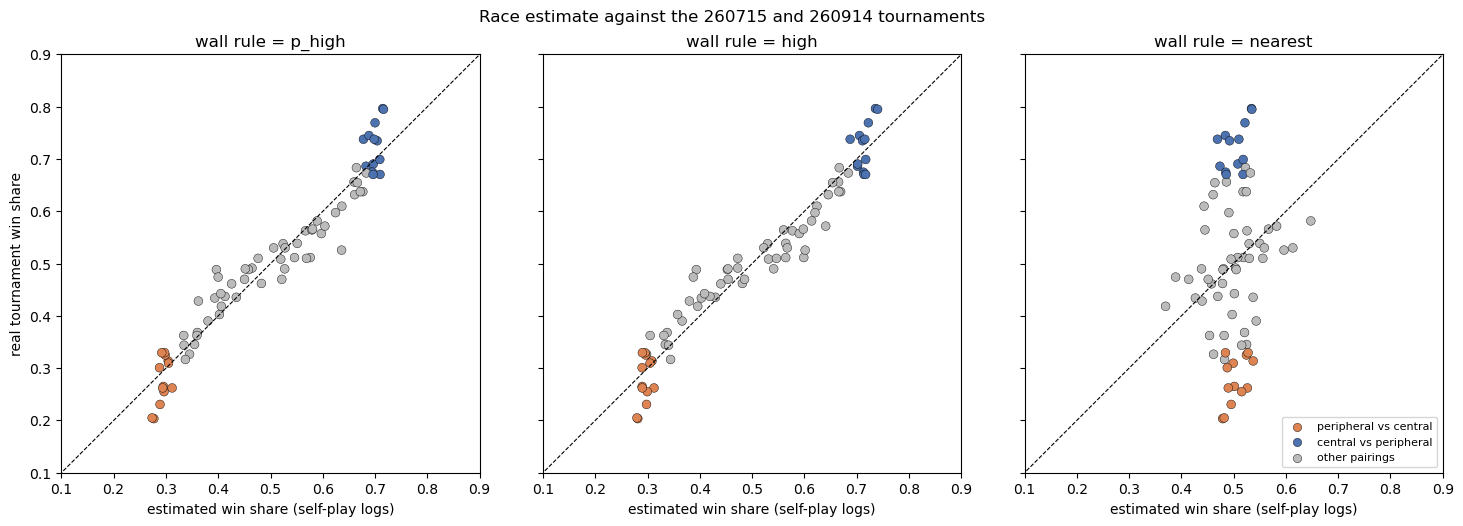

,tournament,focus,opp,actual,est_p_high,est_high,est_nearest
21,260715,15,2,0.231,0.289,0.298,0.495
24,260715,15,20,0.203,0.277,0.281,0.479
25,260715,15,22,0.205,0.273,0.280,0.482
42,260715,26,2,0.314,0.304,0.309,0.537
46,260715,26,20,0.325,0.298,0.296,0.524
47,260715,26,22,0.330,0.297,0.295,0.528
49,260715,36,2,0.309,0.305,0.305,0.499
53,260715,36,20,0.330,0.292,0.290,0.484
54,260715,36,22,0.301,0.288,0.290,0.488
60,260914_vs_260723,17,14,0.262,0.312,0.312,0.526


In [33]:
# plot the estimated against the real win shares for both target rules
col = {'peripheral vs central': '#DD8452', 'central vs peripheral': '#4C72B0'}
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, tg in zip(axes, RULES):
    c = check['pairing'].map(col).fillna('#BBBBBB')
    ax.scatter(check[f'est_{tg}'], check['actual'], s=40, c=c, edgecolor='black', linewidth=0.3)
    ax.plot([0, 1], [0, 1], color='black', lw=0.8, ls='--')
    ax.set_xlim(0.1, 0.9); ax.set_ylim(0.1, 0.9); ax.set_aspect('equal')
    ax.set_xlabel('estimated win share (self-play logs)')
    ax.set_title(f"wall rule = {tg}")
axes[0].set_ylabel('real tournament win share')
for lab, cc in list(col.items()) + [('other pairings', '#BBBBBB')]:
    axes[-1].scatter([], [], c=cc, edgecolor='black', linewidth=0.3, label=lab)
axes[-1].legend(fontsize=8, loc='lower right')
plt.suptitle('Race estimate against the 260715 and 260914 tournaments', y=1.0)
plt.tight_layout(); plt.show()

# list the peripheral-against-central pairs under each rule
check[pc][['tournament', 'focus', 'opp', 'actual'] + [f'est_{tg}' for tg in RULES]].round(3)

### Why the nearer-wall rule fails

The share of each entrant's self-play wins taken at High, split by which lit wall was nearer the
winner at slice onset. `n` columns count the won trials in each case. If the models went to the
nearer wall, `p_high_when_low_nearer` would be close to 0.

In [34]:
# split each entrant's High share by which lit wall was nearer the winner
rows = []
for (b, m), lab in ENTRANT_STRATEGY.items():
    w = race_entrants[(race_entrants['batch'] == b) & (race_entrants['model'] == m) & race_entrants['won']]
    hn = w['d_high'] <= w['d_low']
    rows.append(dict(entrant=f'{b}_{m:04d}', strategy=lab, p_high=w['chose_high'].mean(),
                     p_high_when_high_nearer=w.loc[hn, 'chose_high'].mean(), n_high_nearer=int(hn.sum()),
                     p_high_when_low_nearer=w.loc[~hn, 'chose_high'].mean(), n_low_nearer=int((~hn).sum())))
pd.DataFrame(rows).set_index('entrant').round(3)

,strategy,p_high,p_high_when_high_nearer,n_high_nearer,p_high_when_low_nearer,n_low_nearer
entrant,,,,,,
260715_0002,central,0.854,0.962,105,0.731,93
260715_0020,central,0.869,0.958,120,0.731,78
260715_0022,central,0.909,0.972,109,0.831,89
260715_0010,intermediate,0.782,0.827,104,0.730,89
260715_0014,intermediate,0.884,1.000,92,0.783,106
260715_0015,peripheral,0.843,0.979,95,0.718,103
260715_0026,peripheral,0.692,0.942,104,0.415,94
260715_0036,peripheral,0.747,0.989,88,0.555,110
260914_0014,central,1.000,1.000,118,1.000,80


**Interpretation**

- When High is the nearer wall, every entrant takes it on 0.83-1.00 of wins.
- When Low is nearer, they still take High on 0.42-1.00 of wins. The three alcove-dwellers of 260715
  take High on 0.718 (model 15), 0.415 (26) and 0.555 (36) of those wins.
- So none of these models goes to the nearer wall as a rule. The `nearest` rule sends them to a
  close Low wall far more often than they go, which makes them look faster than they are.
- These shares come from won trials, so they describe the wall a model reaches when it wins.

**Interpretation**

- With the `p_high` rule, estimated and real win shares correlate at 0.967 over 76 ordered pairs,
  with a mean error of 0.031. Score per trial does as well (r = 0.969, mean error 0.030).
- For a peripheral model against a central one, the estimate errs slightly in the peripheral model's
  favour (win share +0.018, score per trial +0.034).
- The worst case is 260715_0015, estimated at 0.273-0.289 against a real 0.203-0.231. The other
  peripheral-central pairs are within 0.05.
- The `high` rule gets win share about as right (mean error 0.033) but overstates score (mean error
  0.066), as it scores every win at 1.0.
- The `nearest` rule fails (r = 0.134) and overrates peripheral models against central ones by 0.228.
  The table below shows why.
- Each pair here is a single draw, so a pair's estimate carries draw noise of a few hundredths. The
  agreement is over 76 pairs.

### Every 260929 model against the central group

Each model raced against each other model of the batch with the checked estimate (`p_high` rule).
Each pair is averaged over five random draws of wall choice and timing.
`win_vs_central` is its mean estimated win share against the 27 central models (excluding itself),
and `win_vs_peripheral` against the six peripheral models. 0.5 is an even match.
`score_vs_central` is its mean score per trial against the central models, and
`score_rate_vs_central` its own score per second in those races. For comparison, a
central model racing other central models takes about half the trials at about 2 s each.

`selfplay_score_rate` is the batch fingerprint's `score_rate` (both agents together) halved, so it
reads per agent like the estimate.

**How to read the figure.** One bar per model, ranked by estimated win share against the central
group. Blue = central, orange = peripheral, and the dashed line marks an even match.

**Why it is plotted.** It places model 32 against the central models on the measure self-play
cannot give, and beside the other peripheral models.

race_estimates_260929: loaded from cache


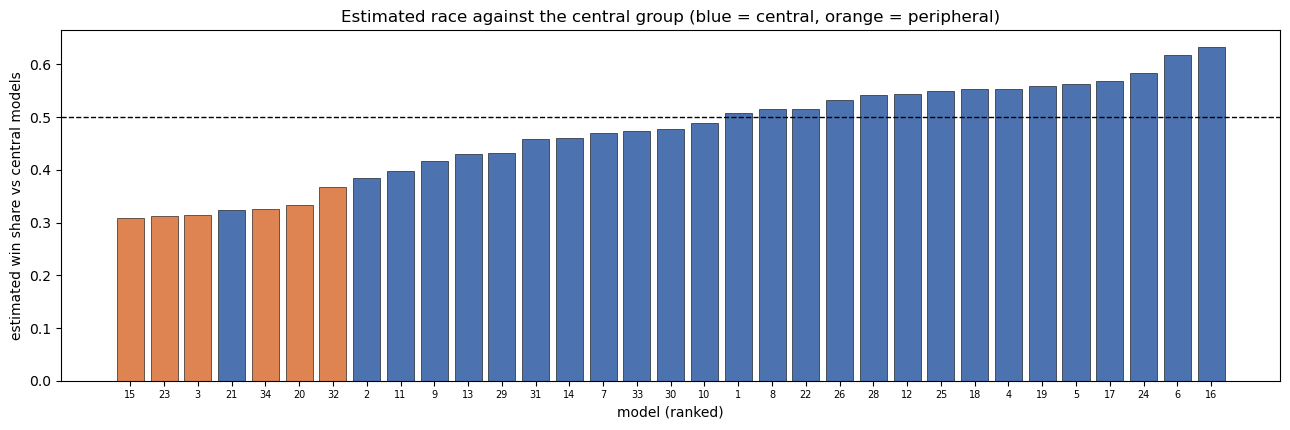

central models racing central models: median score_vs_central 0.515, score_rate_vs_central 0.257


,strategy,p_high,win_vs_central,win_vs_peripheral,score_vs_central,score_rate_vs_central,selfplay_score_rate
3,peripheral,0.778,0.314,0.515,0.268,0.142,0.196
15,peripheral,0.763,0.309,0.458,0.260,0.140,0.188
20,peripheral,0.869,0.333,0.536,0.303,0.163,0.179
23,peripheral,0.833,0.313,0.478,0.275,0.148,0.183
32,peripheral,0.717,0.367,0.556,0.300,0.167,0.233
34,peripheral,0.828,0.326,0.465,0.287,0.157,0.189
21,central,1.000,0.324,0.534,0.324,0.169,0.195
8,central,1.000,0.515,0.689,0.515,0.257,0.244
16,central,1.000,0.633,0.696,0.633,0.324,0.250


In [35]:
N_DRAWS = 5                         # random draws of wall choice and timing, averaged per pair


def batch_estimates():
    ''' Return every model's estimate against every other model, averaged over N_DRAWS draws. '''

    est = []
    for f in ALL_MODELS:
        rf = race_df[race_df['model'] == f]
        for o in ALL_MODELS:
            if o == f:
                continue
            ro = race_df[race_df['model'] == o]
            draws = pd.DataFrame([rc.estimate_matchup(rf, ro, seed=s) for s in range(N_DRAWS)])
            est.append(dict(focus=f, opp=o, **draws.mean().to_dict()))
    return pd.DataFrame(est)


# race every model against every other model of the batch
est = data_saving.cached(f'race_estimates_{BATCH}', batch_estimates, recompute=RECOMPUTE,
                         stamp=(tuple(ALL_MODELS), N_DRAWS, 'p_high'))
est['opp_strategy'] = est['opp'].map(fp_i['strategy'])

# summarise each model against each group
vs = est.groupby(['focus', 'opp_strategy'])[['win_share', 'score_per_trial', 'score_rate']].mean().unstack()
vs = pd.DataFrame({'strategy': fp_i['strategy'], 'p_high': fp_i['p_high'],
                   'win_vs_central': vs[('win_share', 'central')],
                   'win_vs_peripheral': vs[('win_share', 'peripheral')],
                   'score_vs_central': vs[('score_per_trial', 'central')],
                   'score_rate_vs_central': vs[('score_rate', 'central')],
                   'selfplay_score_rate': fp_i['score_rate'] / 2}).sort_values('win_vs_central')

# plot each model's estimated win share against the central group
fig, ax = plt.subplots(figsize=(13, 4.4))
x = np.arange(len(vs))
ax.bar(x, vs['win_vs_central'], color=vs['strategy'].map(mc.STRAT_PALETTE), edgecolor='black', linewidth=0.4)
ax.axhline(0.5, color='black', ls='--', lw=1)
ax.set_xticks(x); ax.set_xticklabels(vs.index, fontsize=7)
ax.set_xlabel('model (ranked)'); ax.set_ylabel('estimated win share vs central models')
ax.set_title('Estimated race against the central group (blue = central, orange = peripheral)')
plt.tight_layout(); plt.show()

print("central models racing central models: median score_vs_central "
      f"{vs.loc[vs.strategy == 'central', 'score_vs_central'].median():.3f}, score_rate_vs_central "
      f"{vs.loc[vs.strategy == 'central', 'score_rate_vs_central'].median():.3f}")
vs.loc[PERIPHERAL + vs[vs.strategy == 'central'].index[[0, 13, -1]].tolist()].round(3)

In [36]:
# show how much one draw of wall choice and timing moves model 32's estimate
draws = [np.mean([rc.estimate_matchup(r32, race_df[race_df['model'] == o], seed=s)['win_share']
                  for o in CENTRAL]) for s in range(5)]
print(f"model {FOCUS} win share vs central, single draws: {np.round(draws, 3)}, mean {np.mean(draws):.3f}")

model 32 win share vs central, single draws: [0.381 0.381 0.347 0.368 0.36 ], mean 0.367


**Interpretation**

- Model 32's estimated win share against the central group is 0.367 (single draws 0.347-0.381).
  That is the highest of the six peripheral models (0.309-0.367). Every central model except
  model 21 (0.324) is higher.
- Against the other peripheral models it would win 0.556.
- Per trial it would score 0.300 against central models, level with model 20 (0.303). Model 32
  wins more races but takes Low more often (`p_high` 0.717 against 0.869). A central model in the
  same races scores a median 0.515.
- Per second it would score 0.167 against central models, against a median of 0.257 for a central
  model. In self-play it scores 0.233 per agent.
- The tournament check found a small bias in the peripheral model's favour (+0.018 in win share,
  +0.034 in score), so a real tournament would be expected to land near or slightly below these.

### Conclusion on model 32

- **It is a competent mover.** It runs the tightest, among the fastest and the shortest routes of
  the batch (r = 0.993, slope 0.121 s per unit, winning route 17.3 units).
- **Its self-play score rate is mostly due to self-play.** 0.434 of its wins start in the lit
  alcove, and its trial time is the faster of two alcove-dwellers. A central opponent starts about
  17-18 units from every wall, so model 32 wins against it mainly when it already stands in or
  beside a lit alcove.
- **Against central models it would lose about two races in three.** Estimated win share 0.367,
  score per trial 0.300 against 0.515 for a central model, and score rate 0.167 against 0.257. It
  wins the most races of the peripheral models, but its frequent Low choices leave it level with
  model 20 on score.
- **It wins by position, not by choice.** It chooses High least (0.717) and often never sees a
  trial wall (0.167 of trials).
- **Direct test.** A short tournament of model 32 against two typical 260929 central models and one
  other peripheral model would check these estimates.

## Stage 6 - what the agents sense, and missed adjacent High walls

Peripheral agents whose nearer lit wall is the High wall of the neighbouring alcove go to it on about
four trials in five. On the rest they go to the far Low wall instead. This stage asks whether those
misses happen because the agent could not sense the High wall, or could have inferred it and did not.

### The agent's sensor

The repo's visibility method (`trajectory_headangle.get_wall_visible`) models human vision. It is
not what the agents sense. From the Unity source (`SelectivePassThroughRaycast.cs`, the
`PlayerAgent` prefab, the training scenes and the arena prefab `OctagonWallAlcovesHalfDepthFull`):

- The agent casts **7 horizontal rays** from its position, at 0, ±18.3, ±36.7 and ±55 degrees from
  its heading, every physics step. Each ray reports only its first hit. The opponent is passed
  through.
- **Any part of a wall** counts. A wall's two faces and its alcove-back block are three box colliders
  on one GameObject, which takes the `HighWall` or `LowWall` tag when lit. So the inside of a lit
  alcove reads as that wall.
- **Trigger boxes are sensed too.** They are switched on at trial start, fill the back 1.5 units of
  each alcove, and take the `HighWallTrigger` or `LowWallTrigger` tag when lit.
- **Unlit walls are sensed as unlit.** Their tag is not in the detection list, so the ray returns a
  distance with no tag.
- A ray does not detect a collider it starts inside. An agent standing in a trigger box does not
  see that box, but does see its own alcove's walls.
- The policy has an LSTM memory, so anything sensed earlier in the trial can still drive behaviour.
- **The two seats sense each other differently.** Rays pass through objects tagged `OpponentAgent`
  and report the nearest one's distance on a separate channel, over the full 60-unit ray, walls or
  not. Logged player 0 is the `PlayerAgent` and player 1 the `OpponentAgent` (`ArenaLogger.cs`).
  Player 0 therefore senses player 1 through walls. Player 1's rays stop at player 0's body, which
  reads as an untagged distance like an unlit wall and hides what is behind it.
- The trained model's ray input has 42 values (7 rays x 6), which confirms the sensor feeds the network.

`analysis/agent_raycast.py` replays the 7 rays in 2D from the logged position and the raw logged
yaw, with no smoothing, and blocks player 1's rays at player 0's body (radius 0.6). It uses the repo's physical wall geometry (wall face 17.355, alcove back
20.355, alcove 5.02 wide), which matches the prefab at arena scale 1.5. A wall counts as sensed on a
frame if any ray's first hit is any part of it. The geometry is unit-tested in
`tests/test_agent_raycast.py`.

**How to read the figure.** Two top-down views of the arena (grey outline, physical walls and
alcoves). The black dot is an agent and the arrow its heading. Each line is one of the 7 rays,
drawn to its first hit and coloured by the wall it hits (legend). The dashed boxes are the trigger
boxes. Left, an agent at the centre facing wall 1. Right, an agent at the back of wall 3's alcove
facing the centre. The title of the right panel lists every wall any ray can reach from that
position, over all headings in 0.5 degree steps.

**Why it is plotted.** It shows what the sensor reads from the two places agents wait, and that from
the back of an alcove no heading lets a ray reach either neighbouring wall.

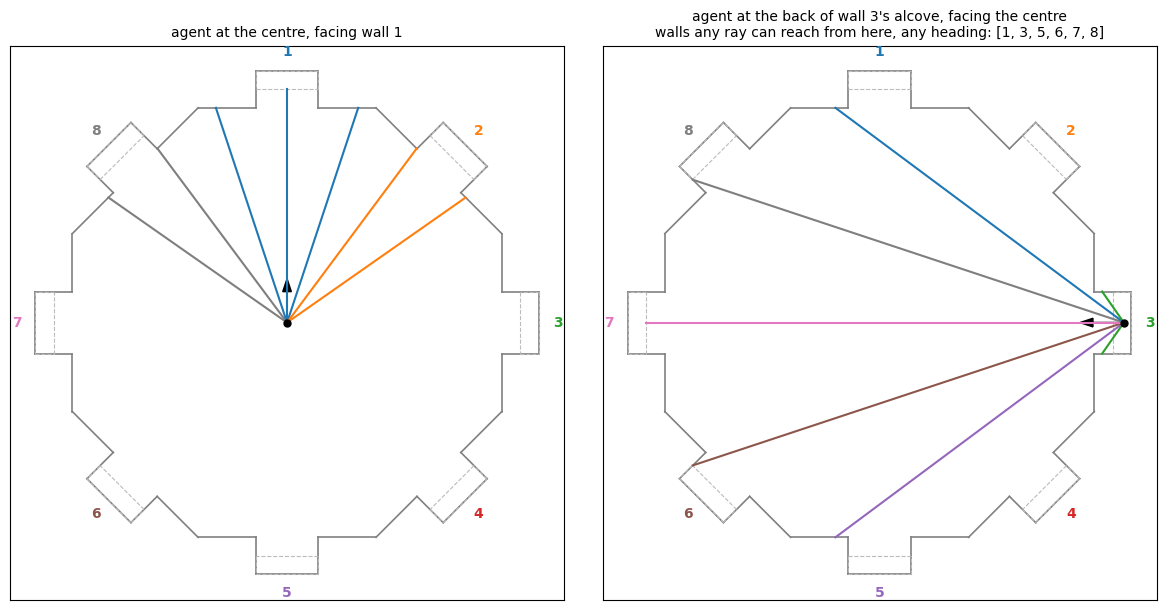

In [37]:
import globals
import analysis.agent_raycast as ar
import trajectory_analysis.visibility_occlusion as vo

# draw the arena, the trigger boxes and an agent's 7 rays
seg, seg_ids, seg_kinds = ar.get_sensor_segments()
wall_col = dict(zip(range(1, 9), sns.color_palette('tab10', 8)))
g = vo.get_physical_geometry()
eye_alcove = np.array(vo.wall_frame_to_arena(g['alcove_back'] - globals.PLAYER_RADIUS, 0.0, 2))
cases = [('agent at the centre, facing wall 1', np.zeros(2), 0.0),
         ('agent at the back of wall 3\'s alcove, facing the centre', eye_alcove, np.radians(45 * 2 + 180))]

# list every wall a ray can reach from the alcove back, over all headings
yaws = np.radians(np.arange(0, 360, 0.5))
reach_ids, _, _ = ar.cast_rays(np.repeat(eye_alcove[None], len(yaws), 0), yaws)
reachable = sorted(set(reach_ids.ravel().tolist()))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, (title, eye, yaw) in zip(axes, cases):
    for (a, b), k in zip(seg, seg_kinds):
        ax.plot([a[0], b[0]], [a[1], b[1]], color='grey' if k == ar.KIND_WALL else '#BBBBBB',
                lw=1.2 if k == ar.KIND_WALL else 0.8, ls='-' if k == ar.KIND_WALL else '--')
    ids, kinds, dist = ar.cast_rays(eye[None], [yaw])
    for off, w, dd in zip(ar.RAY_OFFSETS_DEG, ids[0], dist[0]):
        a = yaw + np.radians(off)
        ax.plot([eye[0], eye[0] + dd * np.sin(a)], [eye[1], eye[1] + dd * np.cos(a)], color=wall_col[w], lw=1.5)
    ax.plot(*eye, 'ko', ms=5)
    ax.arrow(eye[0], eye[1], 2.5 * np.sin(yaw), 2.5 * np.cos(yaw), head_width=0.7, color='black')
    for w in range(1, 9):
        x, z = vo.wall_frame_to_arena(g['alcove_back'] + 1.5, 0.0, w - 1)
        ax.annotate(str(w), (x, z), ha='center', va='center', fontsize=10, color=wall_col[w], weight='bold')
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title, fontsize=10)
axes[1].set_title(f"agent at the back of wall 3's alcove, facing the centre\n"
                  f"walls any ray can reach from here, any heading: {reachable}", fontsize=10)
plt.tight_layout(); plt.show()

### Checks on the sensor model

**Trigger boxes.** If the trigger box is placed right, an agent whose body (radius 0.61) overlaps a
lit trigger box at slice onset wins on the first physics step, and no other agent does. The table
counts agent-trials where the opponent was not also overlapping a lit box. `instant_win` is the
share won in under 0.05 s.

**Behaviour.** An agent should sense the wall it heads for before it commits to it. For trials over
1.5 s, the table gives the share where the target wall was sensed at or before the commit frame,
under the ray model and under the human-vision wedge. The commit frame is the first frame the agent
has closed on the target wall by 1 unit more than on the other lit wall. The target is the wall
reached for a winner. For a loser it is the lit wall whose distance fell more over the trial
(this matches the reached wall on 0.995 of won trials over 0.5 s). `lag_s` is the median time from
first sensing to commit. Two central models (1 and 25) are included for reference.

The sensing table is built from the logs once and cached.

In [38]:
SENSE_MODELS = PERIPHERAL + [1, 25]
sense = data_saving.cached(f'agent_sensing_{BATCH}',
                           lambda: ar.collect_sensing_table(SIM_DATA_FOLDER, SENSE_MODELS, verbose=False),
                           recompute=RECOMPUTE, stamp=(tuple(SENSE_MODELS), 'v4'))
sense['group'] = np.where(sense['model'].isin(PERIPHERAL), 'peripheral', 'central')

# check whether each agent's body overlaps a lit trigger box at slice onset
front, back, half = ar.get_trigger_boxes()


def overlaps_box(x, z, wall):
    ''' Return whether an agent at x, z overlaps a wall's trigger box. Takes the position and wall id. '''

    p, q = vo.arena_to_wall_frame(np.array([[x, z]]), wall - 1)
    return np.hypot(max(front - p[0], 0, p[0] - back), max(abs(q[0]) - half, 0)) < globals.PLAYER_RADIUS


sense['in_lit_trigger'] = [overlaps_box(x, z, h) or overlaps_box(x, z, l)
                           for x, z, h, l in zip(sense.x0, sense.z0, sense.high_wall, sense.low_wall)]
other = sense.set_index(['model', 'trial_num', 'player'])['in_lit_trigger']
sense['opp_in_lit_trigger'] = [other.loc[(m, t, 1 - p)] for m, t, p in zip(sense.model, sense.trial_num, sense.player)]
sense['instant_win'] = sense['won'] & (sense['rt_s'] < 0.05)
alone = sense[~sense['opp_in_lit_trigger']]
display(alone.groupby('in_lit_trigger').agg(agent_trials=('won', 'size'), instant_win=('instant_win', 'mean')).round(3))
print(f"trials ending in under 0.05 s with neither agent on a lit box: "
      f"{int(((sense.rt_s < 0.05) & ~sense.in_lit_trigger & ~sense.opp_in_lit_trigger).sum())}")

# take each agent's target wall and commit frame
sense['toward_high'] = (sense.d_high0 - sense.d_high_end) > (sense.d_low0 - sense.d_low_end)
sense['went_high'] = np.where(sense['won'], sense['chose_high'], sense['toward_high'])
sense['target'] = np.where(sense['went_high'], sense['high_wall'], sense['low_wall'])
sense['commit'] = np.where(sense['went_high'], sense['commit_high'], sense['commit_low'])
long_ = sense[(sense.rt_s > 1.5) & (sense.commit >= 0)].copy()
for m in ('ray', 'wedge'):
    first = np.array([r[f'{m}_first_{w}'] for w, (_, r) in zip(long_.target, long_.iterrows())])
    long_[f'{m}_sensed_before_commit'] = (first >= 0) & (first <= long_.commit)
    long_[f'{m}_lag_s'] = np.where(first >= 0, (long_.commit - first) / mc.FS, np.nan)
long_.groupby('group').agg(agent_trials=('won', 'size'), median_commit_s=('commit', lambda c: np.median(c) / mc.FS),
                           ray_sensed_before=('ray_sensed_before_commit', 'mean'),
                           wedge_seen_before=('wedge_sensed_before_commit', 'mean'),
                           ray_lag_s=('ray_lag_s', 'median'), wedge_lag_s=('wedge_lag_s', 'median')).round(3)

agent_sensing_260929: loaded from cache


,agent_trials,instant_win
in_lit_trigger,,
False,2376,0.000
True,253,0.992


trials ending in under 0.05 s with neither agent on a lit box: 0


,agent_trials,median_commit_s,ray_sensed_before,wedge_seen_before,ray_lag_s,wedge_lag_s
group,,,,,,
central,790,0.25,0.699,0.729,0.10,0.11
peripheral,1477,0.80,0.995,0.995,0.72,0.76


**Interpretation**

- The figure shows the main difference from the human-vision model. From the back of an alcove, rays
  reach walls 1, 3, 5, 6, 7 and 8 at some heading, but never the neighbouring walls 2 and 4. The
  agent's own wall is sensed through its alcove sides, which the human model treats as hidden.
- The trigger boxes are placed right. Agents overlapping a lit box at onset win in under 0.05 s on
  0.992 of trials (n = 253). Agents not overlapping one never do (0.000, n = 2376). No trial ends
  that fast without an overlap.
- The behavioural check does not separate the two sensing models. Peripheral agents sense their
  target before committing on 0.995 of trials under both. Central agents score only 0.700 and 0.729,
  because they commit at a median 0.25 s. They are already moving at slice onset, so the 1-unit rule
  fires before any choice.
- So the ray model rests on the Unity source and the unit tests, plus the trigger-box check, not on
  behaviour.

### The loser's choice

A trial ends when either agent reaches a lit wall, so the loser's choice is never logged. Most
questions about which wall an agent goes for need it, as about half of all agent-trials are losses.
`analysis/agent_loser_choice.py` calls a loser's choice only where the end of its trajectory makes it
clear, and makes no call otherwise. Dropping many losers is intended.

The human data uses `analysis/loser_inferred_choice.py`. It compares the movement direction over the
last third of the trajectory with the direction to every alcove centre, and accepts the best-aligned
lit wall if the mean cosine is above 0.875 or the player ends within 4 units of it. Two things make
that too loose for agents that wait in alcoves. Leaving an alcove points an agent at the far walls,
whichever wall it is going to. And an agent running past the front of a lit alcove comes within 4
units of it on its way to the other wall.

The agent version uses two rules, tried in order.
1. **At the alcove.** The agent ends past a lit wall's face (inside its alcove), within the alcove's
   width, and has closed on that alcove over the last 10 frames (0.2 s).
2. **Aligned.** Over the last 25 frames (0.5 s), the movement direction points at the
   same wall on every frame, with a mean cosine of at least 0.94 (about 20 degrees) to it and a mean
   lead of at least 0.10 over the next-best wall. That wall must be lit.

The movement direction and its cosine to each alcove come from
`trajectory_direction.cosine_similarity_throughout_trajectory` (Savitzky-Golay smoothed, window 11), the
function the human loser's-choice and visibility analyses use.

Everything else gets no call. `too short` means under 37 frames (the window plus the smoothing).
`stopped` means the smoothed movement fell under 0.04 units per frame in the final window. `ambiguous` means the alignment changed wall
or was weak. `aligned to unlit wall` means it was heading for a wall that is not lit.

**How to read the figure.** The top row shows one peripheral loser for each of four outcomes, top-down. Red is the
High wall, blue the Low wall, grey the rest. The thin grey line is the loser's path from slice onset
and the thick black line its last 25 frames, the window the aligned rule reads. The square is the
start and the circle the end. Where a wall is called, a dashed line joins the end to that alcove. The
title gives the outcome, with the mean cosine and lead for the aligned rule. The bottom panel gives
the share of all peripheral losers in each outcome. Blue bars are calls, grey bars no call.

**Why it is plotted.** It shows what each rule accepts and rejects, and how many losers keep a call.

agent_trajectories_260929_peripheral: loaded from cache


/home/tom/repos/octagon_analysis/trajectory_analysis/trajectory_vectors.py:274: RuntimeWarning: invalid value encountered in divide
  cosine_similarities = dot_products / (player_to_alcove_vector_norms_trajectory


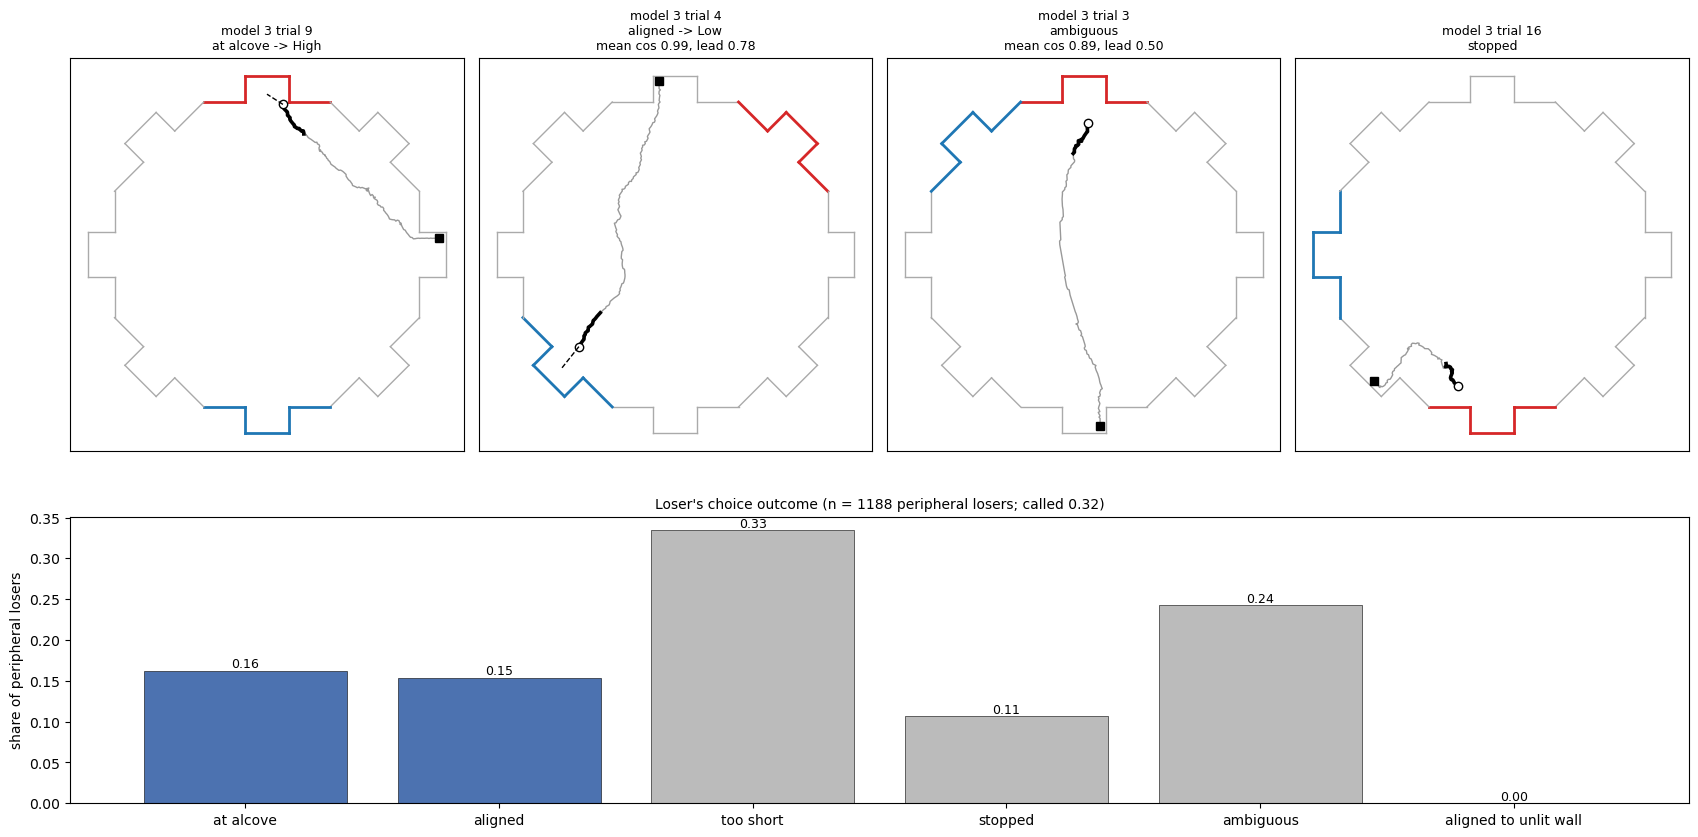

rule
at alcove                0.162
aligned                  0.154
too short                0.334
stopped                  0.107
ambiguous                0.242
aligned to unlit wall    0.000
model 3 trial 4 (aligned): mean cos 0.99, lead 0.78
model 3 trial 3 (ambiguous): mean cos 0.89, lead 0.50


In [39]:
import analysis.agent_loser_choice as lc
import analysis.loser_inferred_choice as loser_inferred_choice
from analysis.race_estimate import ALCOVE_CENTRES

# get every peripheral agent-trial's trajectory, once
traj = data_saving.cached(f'agent_trajectories_{BATCH}_peripheral',
                          lambda: lc.collect_trajectories(SIM_DATA_FOLDER, PERIPHERAL, verbose=False),
                          recompute=RECOMPUTE, stamp=tuple(PERIPHERAL))

# call each loser's choice
losers = traj[~traj['won']].copy()
calls = [lc.infer_choice(r.xy, r.high_wall, r.low_wall) for r in losers.itertuples()]
losers['call'] = [c[0] for c in calls]
losers['rule'] = [c[1] for c in calls]
losers['trial_s'] = losers['xy'].map(len) / mc.FS
order_rules = list(lc.RULES) + list(lc.NO_CALL)
share = losers['rule'].value_counts(normalize=True).reindex(order_rules).fillna(0)

# pick one example loser per outcome (the first over 1 s, by model and trial). No peripheral loser
# was heading for an unlit wall, so that outcome has no example
examples = [losers[(losers.rule == r) & (losers.trial_s > 1)].iloc[0] for r in
            ('at alcove', 'aligned', 'ambiguous', 'stopped')]

fig = plt.figure(figsize=(17, 9))
gs = fig.add_gridspec(2, 4, height_ratios=[1.35, 0.65])
for i, ex in enumerate(examples):
    ax = fig.add_subplot(gs[0, i])
    for (a, b), w, k in zip(seg, seg_ids, seg_kinds):
        if k != ar.KIND_WALL:
            continue
        col = '#D62728' if w == ex.high_wall else '#1F77B4' if w == ex.low_wall else '#AAAAAA'
        ax.plot([a[0], b[0]], [a[1], b[1]], color=col, lw=2 if col != '#AAAAAA' else 1)
    xy = ex.xy
    ax.plot(xy[:, 0], xy[:, 1], color='#999999', lw=1)
    ax.plot(xy[-lc.END_WINDOW:, 0], xy[-lc.END_WINDOW:, 1], color='black', lw=2.6)
    ax.plot(*xy[0], 'ks', ms=6); ax.plot(*xy[-1], 'ko', ms=6, mfc='white')
    title = ex.rule
    if pd.notna(ex.call):
        c = ALCOVE_CENTRES[int(ex.call) - 1]
        ax.plot([xy[-1, 0], c[0]], [xy[-1, 1], c[1]], color='black', ls='--', lw=1)
        title += f" -> {'High' if ex.call == ex.high_wall else 'Low'}"
    if ex.rule in ('aligned', 'ambiguous'):
        cos, _ = lc.alignment(xy)
        srt = np.sort(cos, axis=1)
        title += f"\nmean cos {srt[:, -1].mean():.2f}, lead {(srt[:, -1] - srt[:, -2]).mean():.2f}"
    ax.set_title(f"model {int(ex.model)} trial {int(ex.trial_num)}\n{title}", fontsize=9)
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])

ax = fig.add_subplot(gs[1, :])
ax.bar(range(len(order_rules)), share.values,
       color=['#4C72B0' if r in lc.RULES else '#BBBBBB' for r in order_rules], edgecolor='black', lw=0.4)
for i, v in enumerate(share.values):
    ax.annotate(f"{v:.2f}", (i, v), ha='center', va='bottom', fontsize=9)
ax.set_xticks(range(len(order_rules))); ax.set_xticklabels(order_rules)
ax.set_ylabel('share of peripheral losers')
ax.set_title(f"Loser's choice outcome (n = {len(losers)} peripheral losers; called {losers.call.notna().mean():.2f})", fontsize=10)
plt.tight_layout(); plt.show()

# print the outcome shares and the example losers' alignment values the figure shows
print(share.round(3).to_string())
for ex in examples:
    if ex.rule in ('aligned', 'ambiguous'):
        cos, _ = lc.alignment(ex.xy)
        srt = np.sort(cos, axis=1)
        print(f"model {int(ex.model)} trial {int(ex.trial_num)} ({ex.rule}): mean cos {srt[:, -1].mean():.2f}, lead {(srt[:, -1] - srt[:, -2]).mean():.2f}")

### Checking the loser's choice against winners

A winner's trajectory ends at the wall it chose, so cutting it short gives a trajectory that looks
like a loser's but whose answer is known. Every peripheral winner is cut every 10 frames, from 37
frames up to its last frame, and the rule is run on each cut. The human rule is run on the same cuts
for reference, through `loser_inferred_choice.infer_loser_choice_trajectory`.

Table columns. `cuts` is the number of cut trajectories, `called` the share given a call and
`correct` the share of calls that match the wall reached. The first table compares the two rules
overall and by rule. The next tables break the agent rule down by how long the trajectory had run
(`cut_s`), by how far the agent still was from the wall it reached (`dist_left`), and by whether it
went on to reach High or Low. `losers_share` gives the share of real losers whose trial ended in each
`cut_s` band, to show which bands matter for losers.

In [40]:
# cut every peripheral winner and call each cut
check_cuts = data_saving.cached(f'loser_choice_check_{BATCH}', lambda: lc.truncation_check(traj),
                                recompute=RECOMPUTE, stamp=(tuple(PERIPHERAL), lc.COS_MIN, lc.MARGIN, lc.END_WINDOW, lc.SMOOTH_WINDOW))


import warnings

# run the human rule on the same cuts
human = []
for _, t in traj[traj['won']].iterrows():
    for k in range(lc.END_WINDOW + lc.SMOOTH_WINDOW + 1, len(t.xy), 10):
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', RuntimeWarning)          # stationary stretches give NaN cosines
            wall, accepted = loser_inferred_choice.infer_loser_choice_trajectory(t.xy[:k].T, (t.high_wall, t.low_wall))
        human.append(dict(accepted=accepted, correct=accepted and wall == t.chosen_wall))
human = pd.DataFrame(human)

summary = pd.DataFrame([
    dict(rule='agent rule (all)', cuts=len(check_cuts), called=check_cuts.accepted.mean(),
         correct=check_cuts[check_cuts.accepted].correct.mean(), wrong_calls=int((check_cuts.accepted & ~check_cuts.correct).sum())),
    *[dict(rule=f'agent rule: {r}', cuts=len(check_cuts), called=(check_cuts.rule == r).mean(),
           correct=check_cuts[check_cuts.rule == r].correct.mean(),
           wrong_calls=int(((check_cuts.rule == r) & ~check_cuts.correct).sum())) for r in lc.RULES],
    dict(rule='human rule', cuts=len(human), called=human.accepted.mean(),
         correct=human[human.accepted].correct.mean(), wrong_calls=int((human.accepted & ~human.correct).sum()))])
summary.set_index('rule').round(4)

loser_choice_check_260929: loaded from cache


,cuts,called,correct,wrong_calls
rule,,,,
agent rule (all),11047,0.3166,0.9986,5
agent rule: at alcove,11047,0.0740,1.0000,0
agent rule: aligned,11047,0.2425,0.9981,5
human rule,11047,0.7797,0.9518,415


In [41]:
def by_band(col, bins):
    ''' Return coverage and accuracy of the agent rule within bands of one cut column. '''

    c = check_cuts.assign(band=pd.cut(check_cuts[col], bins))
    out = c.groupby('band', observed=True).agg(cuts=('accepted', 'size'), called=('accepted', 'mean'),
                                                correct=('correct', lambda s: s[c.loc[s.index, 'accepted']].mean()))
    return out


time_bins = [0.6, 1.0, 1.5, 2.0, 3.0, 20]
t_tab = by_band('cut_s', time_bins)
t_tab['losers_share'] = pd.cut(losers['trial_s'], time_bins).value_counts(normalize=True).reindex(t_tab.index).values
print(f"losers whose trial ended within 0.6 s (no cut that short is possible): {(losers.trial_s <= 0.6).mean():.3f}")
display(t_tab.round(4))
display(by_band('dist_left', [0, 2, 5, 10, 20, 40]).round(4))

# check by the wall the winner went on to reach, and by what the call said. A wrong Low call is what
# matters most here, as it would make an agent look as if it passed up High
acc = check_cuts[check_cuts.accepted]
wall_tab = pd.DataFrame({
    'cuts': check_cuts.groupby('reached_high').size(),
    'called': check_cuts.groupby('reached_high').accepted.mean(),
    'correct': acc.groupby('reached_high').correct.mean()}).rename(index={True: 'went on to reach High', False: 'went on to reach Low'})
display(wall_tab.round(4))
call_tab = pd.DataFrame({'calls': acc.groupby('call_high').size(), 'correct': acc.groupby('call_high').correct.mean()}
                        ).rename(index={True: 'call says High', False: 'call says Low'})
display(call_tab.round(4))

losers whose trial ended within 0.6 s (no cut that short is possible): 0.334


,cuts,called,correct,losers_share
band,,,,
"(0.6, 1.0]",1581,0.0063,1.0000,0.0013
"(1.0, 1.5]",1579,0.0602,0.9579,0.0063
"(1.5, 2.0]",2270,0.2048,0.9978,0.1037
"(2.0, 3.0]",3097,0.4411,1.0000,0.1808
"(3.0, 20.0]",2520,0.6194,1.0000,0.7080


,cuts,called,correct
band,,,
"(0, 2]",825,0.9491,1.0000
"(2, 5]",1534,0.4896,1.0000
"(5, 10]",2375,0.4387,0.9990
"(10, 20]",3730,0.2276,0.9965
"(20, 40]",2583,0.0279,0.9861


,cuts,called,correct
reached_high,,,
went on to reach Low,181,0.1657,0.9000
went on to reach High,10866,0.3191,0.9994


,calls,correct
call_high,,
call says Low,29,0.9310
call says High,3468,0.9991


**Interpretation**

- The rule calls 0.316 of the 1188 peripheral losers, 0.162 at the alcove and 0.154 aligned.
- 0.334 of losers are too short, as the opponent won from inside a lit alcove before the agent had a
  choice to read. Another 0.242 are ambiguous and 0.107 stopped. No loser was heading for an unlit wall.
- The rule is conservative. In the ambiguous example the agent is plainly heading for High, but its
  mean cosine (0.89) is under the 0.94 cut.
- On cut winners the rule is right on 0.9986 of calls (5 wrong). At-alcove calls are never wrong and
  aligned calls are right on 0.9981.
- The human rule calls far more (0.780) but is wrong 415 times (0.952 right). It is not safe for
  agents.
- Calls get more frequent the longer the trajectory has run, from 0.060 at 1.0-1.5 s to 0.619 past
  3 s. Accuracy is lowest in the 1.0-1.5 s band (0.958) and 0.998 or above in every other band. 0.708
  of real losers' trials run past 3 s, where every call was right.
- **The weak point is Low.** Only 181 cuts come from winners that went on to reach Low. Those cuts are
  called correctly 0.900 of the time. A "Low" call is right on 0.931 of 29. This rests on few trials,
  because winners rarely go to Low, so a count of Low calls among losers carries more doubt than a
  count of High calls. The tournament check below has far more Low calls.

### Does the opponent's position change the agent's choice?

The question is whether an agent gives up on High, or goes for it more, when it can see its opponent
standing near the High wall. Self-play can't answer it, and this section works through why before
using cross-model tournament matchups instead.

**Self-play.** The first cell counts how often 260929's peripheral agents choose Low when they have
a real choice, and where their Low wins come from. The second compares how many alcoves apart the
two agents of a model start, against random placement (0 = the same alcove).

In [42]:
import analysis.opponent_response as orsp

# count Low choices among peripheral agent-trials that start off a lit trigger, with a known choice
use = sense[sense['group'] == 'peripheral'].merge(traj[['model', 'trial_num', 'player', 'xy']],
                                                  on=['model', 'trial_num', 'player'])
use['opp_in_lit_trigger'] = [overlaps_box(x, z, h) or overlaps_box(x, z, l)
                             for x, z, h, l in zip(use.opp_x0, use.opp_z0, use.high_wall, use.low_wall)]
use = use[~use.in_lit_trigger & ~use.opp_in_lit_trigger].copy()
use['choice'] = [r.chosen_wall if r.won else lc.infer_choice(r.xy, r.high_wall, r.low_wall)[0] for r in use.itertuples()]
use = use[use['choice'].notna()]
print(f"self-play agent-trials off a lit trigger with a known choice: {len(use)}, "
      f"chose Low on {int((use.choice != use.high_wall).sum())}")

# find where the peripheral models' Low wins come from
won = sense[(sense.group == 'peripheral') & sense.won]
low_wins = won[~won.chose_high]
print(f"self-play wins at Low: {len(low_wins)} of {len(won)}; "
      f"won in under 0.05 s (already on the lit Low trigger): {(low_wins.rt_s < 0.05).mean():.3f}")

# count how far apart the two agents of a model start, in alcoves
p0 = sense[(sense.group == 'peripheral') & (sense.player == 0)]
apart = np.minimum((orsp.own_alcove(p0.x0, p0.z0) - orsp.own_alcove(p0.opp_x0, p0.opp_z0)) % 8,
                   (orsp.own_alcove(p0.opp_x0, p0.opp_z0) - orsp.own_alcove(p0.x0, p0.z0)) % 8)
pd.DataFrame({'self-play': pd.Series(apart).value_counts(normalize=True).sort_index(),
              'random placement': pd.Series({0: 1 / 8, 1: 2 / 8, 2: 2 / 8, 3: 2 / 8, 4: 1 / 8})}).rename_axis('alcoves apart').round(3)

/home/tom/repos/octagon_analysis/trajectory_analysis/trajectory_vectors.py:274: RuntimeWarning: invalid value encountered in divide
  cosine_similarities = dot_products / (player_to_alcove_vector_norms_trajectory


self-play agent-trials off a lit trigger with a known choice: 1167, chose Low on 21
self-play wins at Low: 240 of 1188; won in under 0.05 s (already on the lit Low trigger): 0.950


,self-play,random placement
alcoves apart,,
0,0.519,0.125
1,0.320,0.250
2,0.125,0.250
3,0.019,0.250
4,0.018,0.125


**Interpretation**

- 260929's peripheral agents choose Low on only 21 of 1167 agent-trials where they start off a lit
  trigger and their choice is known. There is almost no Low choice for the opponent to explain.
- Their Low wins come from where they stand. 0.950 of the 240 wins at Low came in under 0.05 s, with
  the agent already on the lit Low trigger. So `p_high` around 0.80 for these models reflects position,
  not preference.
- The two agents of a model start in the same alcove on 0.519 of trials and in neighbouring alcoves on
  0.320, against 0.125 and 0.250 for random placement. In self-play, the opponent's position cannot
  be varied apart from the agent's own.

### Cross-model tournaments

The 260715 and 260723 tournaments pit separately trained peripheral models against each other:
260715 models 15, 26 and 36, and 260723 models 1, 23, 33, 35 and 51. Every ordered pair of different
peripheral models is used (26 matchups, both seat orders, about 348 trials each). Self-matchups are
left out. These models were simulated in tournament builds that carry the same ray sensor and seat
tags as above (unchanged since 24 June 2026). The loser's-choice rule is re-checked on these models'
winners below.

The first table compares how far apart the two agents start with a shuffle, in which each agent is
paired with its opponent's position from another trial of the same matchup. If the two models' waiting
places were unrelated, the two columns would match. The next lines test one likely link, the previous
trial: how often an agent starts in the alcove of the wall triggered on the trial before, split by
whether it won that trial.

In [43]:
# load the peripheral-vs-peripheral matchups of both tournaments, once
TOURNAMENT_DIR = os.path.join(data_strings.SIM_DATA_FOLDER, 'tournaments')
TOURNAMENT_PERIPHERAL = {'260715': [15, 26, 36], '260723': [1, 23, 33, 35, 51]}
tour_sense, tour_traj = [], []
for tour, ms in TOURNAMENT_PERIPHERAL.items():
    names = [f'{tour}_{m:04d}' for m in ms]
    folders = [f'{a}__vs__{b}' for a in names for b in names if a != b]
    s_, t_ = data_saving.cached(f'tournament_periph_tables_{tour}',
                                lambda: ar.collect_matchup_tables(os.path.join(TOURNAMENT_DIR, tour), folders, verbose=False),
                                recompute=RECOMPUTE, stamp=(tuple(folders), 'v4'))
    tour_sense.append(s_.assign(tour=tour)); tour_traj.append(t_.assign(tour=tour))
tour_sense = pd.concat(tour_sense, ignore_index=True)
tour_traj = pd.concat(tour_traj, ignore_index=True)
print(f"matchups {tour_sense.matchup.nunique()}, agent-trials {len(tour_sense)}")

# compare how far apart the agents start with a within-matchup shuffle
t0 = tour_sense[tour_sense.player == 0].copy()
t0['own'], t0['opp_own'] = orsp.own_alcove(t0.x0, t0.z0), orsp.own_alcove(t0.opp_x0, t0.opp_z0)
steps_apart = lambda a, b: np.minimum((a - b) % 8, (b - a) % 8)
rng = np.random.default_rng(0)
shuffled = np.concatenate([steps_apart(g.own.values, rng.permutation(g.opp_own.values))
                           for _, g in t0.groupby('matchup') for _ in range(50)])
display(pd.DataFrame({'observed': pd.Series(steps_apart(t0.own.values, t0.opp_own.values)).value_counts(normalize=True).sort_index(),
                      'shuffled': pd.Series(shuffled).value_counts(normalize=True).sort_index()}).rename_axis('alcoves apart').round(3))

# check the link through the previous trial's triggered wall
ts = tour_sense.copy()
ts['own'] = orsp.own_alcove(ts.x0, ts.z0)
prev = ts[ts.player == 0][['matchup', 'trial_num', 'chosen_wall']].assign(trial_num=lambda d: d.trial_num + 1)
prev_won = ts[['matchup', 'trial_num', 'player', 'won']].assign(trial_num=lambda d: d.trial_num + 1)
ts = (ts.merge(prev.rename(columns={'chosen_wall': 'prev_trigger'}), on=['matchup', 'trial_num'])
        .merge(prev_won.rename(columns={'won': 'won_prev'}), on=['matchup', 'trial_num', 'player']))
ts['at_prev_trigger'] = ts.own == ts.prev_trigger
print(f"agents starting in the alcove of the previous trial's triggered wall: {ts.at_prev_trigger.mean():.3f} (1/8 if unrelated)")
print(ts.groupby('won_prev').at_prev_trigger.mean().rename({True: 'won the previous trial', False: 'lost it'}).round(3).to_string())
same = ts[ts.player == 0].merge(ts[ts.player == 1][['matchup', 'trial_num', 'own', 'at_prev_trigger']],
                                on=['matchup', 'trial_num'], suffixes=('', '_opp'))
same = same[same.own == same.own_opp]
print(f"same-alcove starts with both agents at the previous triggered wall: {(same.at_prev_trigger & same.at_prev_trigger_opp).mean():.3f}")

# re-check the loser's-choice rule on these models' winners
tour_check = data_saving.cached('loser_choice_check_tournament_periph', lambda: lc.truncation_check(tour_traj),
                                recompute=RECOMPUTE, stamp=(tuple(sorted(tour_traj.matchup.unique())), lc.COS_MIN, lc.MARGIN, lc.SMOOTH_WINDOW))
acc_t = tour_check[tour_check.accepted]
print(f"loser's choice on cut tournament winners: called {tour_check.accepted.mean():.3f}, correct {acc_t.correct.mean():.4f} "
      f"({int((~acc_t.correct).sum())} wrong of {len(acc_t)}); 'Low' calls correct {acc_t[acc_t.call_high == False].correct.mean():.4f} "
      f"(n {int((acc_t.call_high == False).sum())})")

tournament_periph_tables_260715: loaded from cache
tournament_periph_tables_260723: loaded from cache
matchups 26, agent-trials 18088


,observed,shuffled
alcoves apart,,
0,0.264,0.125
1,0.377,0.250
2,0.190,0.250
3,0.110,0.250
4,0.060,0.125


agents starting in the alcove of the previous trial's triggered wall: 0.606 (1/8 if unrelated)
won_prev
lost it                   0.265
won the previous trial    0.948
same-alcove starts with both agents at the previous triggered wall: 0.953
loser_choice_check_tournament_periph: loaded from cache
loser's choice on cut tournament winners: called 0.299, correct 0.9987 (26 wrong of 20230); 'Low' calls correct 0.9980 (n 4083)


**Interpretation**

- Even separately trained models start in the same alcove on 0.264 of trials, against 0.125 when
  shuffled within matchups.
- The link is the previous trial, not training. 0.606 of agents start in the alcove of the wall
  triggered on the trial before. That is 0.948 of the previous winners, who stay where they won, and
  0.265 of the losers. 0.953 of same-alcove starts have both agents at that wall.
- The walls of the next trial come from a random sequence, so this shared alcove is placed at random
  relative to them. It still ties the opponent's position to the agent's, which is why the comparison
  below works within the agent's own position.
- The loser's-choice rule holds on these models. It is correct on 0.9987 of calls on cut winners
  (26 wrong of 20230), and Low calls, which were thin in 260929, are correct on 0.9980 (n = 4083).

### Building a fair comparison

Three choices keep the comparison free of bias, and each was tested against a control that should
show no effect (opponents near High that the agent never sensed).

- **Outcome.** The agent's heading at 1.0 s after slice onset (`heading_high`): whether its movement over
  the previous 12 frames points more toward the High or the Low alcove. The cosines come from
  `trajectory_direction.cosine_similarity_throughout_trajectory`, as in the human analyses. Every agent gets one
  if the trial lasts past 1.0 s and it is moving, winner or loser. A winner's wall or a called loser's
  choice depends on the outcome of the trial, which the opponent's position also changes.
- **Seen opponent.** An opponent counts as seen only if a ray senses it at slice onset, before any
  movement. Sensing later depends on where the agent turns, so High-goers sweep up the opponents
  standing near High.
- **Strata.** Comparisons are made within the agent's own position (alcoves to High and to Low, mirror
  layouts pooled), and within what it sees at onset (High in view, Low in view). Trials where the two
  agents start in the same alcove are left out, as are trials where either starts on a lit trigger.

`near` means the opponent's onset position is within 15 units of the High alcove centre, which takes
in the neighbouring alcove. The first table shows the versions that failed. `OR` is the
Mantel-Haenszel odds ratio of choosing (or heading for) High, opponent near against far, pooled over
the agent's position. Above 1 means more High with the opponent near. The `control` columns repeat it
for opponents that were never sensed. A sound method should show no effect there.

In [44]:
# build the per agent-trial table for the tournaments, once
tour_table = data_saving.cached('opponent_trial_table_tournaments', lambda: orsp.build_trial_table(tour_sense, tour_traj),
                                recompute=RECOMPUTE, stamp=(tuple(sorted(tour_sense.matchup.unique())), orsp.HEADING_FRAME, 'v4'))
# add the outcome-based choice for the failed versions (winner's wall, or a called loser's choice)
calls = tour_traj.set_index(['matchup', 'trial_num', 'player'])
tour_table['choice'] = [r.chosen_wall if r.won else lc.infer_choice(calls.loc[(r.matchup, r.trial_num, r.player), 'xy'],
                                                                    r.high_wall, r.low_wall)[0] for r in tour_table.itertuples()]
tour_table['chose_high'] = tour_table['choice'] == tour_table['high_wall']
tour_table['near'] = tour_table['opp_d_high'] < orsp.NEAR_HIGH
cells = ['kh', 'kl']

failed = []
known = tour_table[tour_table.choice.notna()]
heading = tour_table[tour_table.heading_high.notna()].assign(heading_high=lambda d: d.heading_high.astype(bool))
for name, df, outcome, seen, unseen in (
        ('winner / called-loser choice, opponent sensed at any time', known, 'chose_high', known.opp_first >= 0, known.opp_first < 0),
        ('heading at 1.0 s, opponent sensed by 1.0 s', heading, 'heading_high',
         (heading.opp_first >= 0) & (heading.opp_first < orsp.HEADING_FRAME), heading.opp_first < 0)):
    a, b = df[seen], df[unseen]
    failed.append(dict(version=name, n=len(a), OR=orsp.mh_odds_ratio(a, a.near, outcome, cells)[0],
                       control_n=len(b), control_OR=orsp.mh_odds_ratio(b, b.near, outcome, cells)[0],
                       control_CI=orsp.bootstrap_or(b, b.near, outcome, cells, n_boot=300).round(2)))
pd.DataFrame(failed).set_index('version').round(2)

opponent_trial_table_tournaments: loaded from cache


/home/tom/repos/octagon_analysis/trajectory_analysis/trajectory_vectors.py:274: RuntimeWarning: invalid value encountered in divide
  cosine_similarities = dot_products / (player_to_alcove_vector_norms_trajectory


,n,OR,control_n,control_OR,control_CI
version,,,,,
"winner / called-loser choice, opponent sensed at any time",5514,1.92,3128,0.15,"[0.1, 0.22]"
"heading at 1.0 s, opponent sensed by 1.0 s",7655,1.42,3105,0.20,"[0.15, 0.27]"


**Interpretation**

- Both earlier versions fail their control. Opponents near High that the agent never sensed give odds
  ratios of 0.15 and 0.20, a strong effect where there can be none.
- In the first version the choice is known only for winners and for losers that can be called, both
  of which depend on what the opponent did.
- In both versions the opponent's sensing is counted over the trial. Agents heading for High sweep up
  an opponent standing near High, and agents heading for Low do not. So 'sensed' fills with High-goers
  and 'never sensed' with Low-goers, whatever the agent does in response.
- Their apparent effects (1.92 and 1.42) are not evidence of a response to the opponent.

### The comparison

Agents that sensed their opponent at slice onset are compared with agents that did not, within the
same position and the same view of the walls (`kh`, `kl`, High in view at onset, Low in view at onset).
Two exposed groups are each set against the same reference group, where the opponent was not sensed:
the opponent seen near High, and the opponent seen far from High.

**Balance table.** Each value is the mean difference (exposed minus reference) within strata,
weighted by the exposed trials in each. `face_high` and `face_low` are the angles (degrees) between
the agent's onset heading and the High and Low alcoves (smaller means facing more toward them), and
`d_high0` and `d_low0` its onset distances to them. Values near 0 mean the groups are matched.

**Result table.** `heading_high` gives the raw share heading for High in each group. `MH_OR` is the
stratified odds ratio with a bootstrap 95% interval. `logit_OR` comes from a logistic regression with
the same strata as fixed effects plus the two facing angles, with its 95% interval and p-value.

In [45]:
import statsmodels.formula.api as smf

# keep agent-trials with a heading at 1.0 s and the two agents in different alcoves
cmp_ = heading[heading.own != heading.opp_own].copy()
cmp_['group'] = np.select([cmp_.opp_seen0 & cmp_.near, cmp_.opp_seen0], ['seen, near High', 'seen, far from High'], default='not seen')
print(cmp_.group.value_counts().to_string())
strata = ['kh', 'kl', 'high_seen0', 'low_seen0']

bal, res = [], []
for grp in ('seen, near High', 'seen, far from High'):
    d = cmp_[cmp_.group.isin([grp, 'not seen'])].copy()
    e = d.group == grp
    bal.append(dict(exposed=grp, **{c: orsp.within_strata_difference(d, e, c, strata)
                                    for c in ('face_high', 'face_low', 'd_high0', 'd_low0')}))
    orr, used = orsp.mh_odds_ratio(d, e, 'heading_high', strata)
    d['exp'], d['y'] = e.astype(int), d.heading_high.astype(int)
    d['cell'] = d[strata].astype(str).agg('_'.join, axis=1)
    m = smf.logit('y ~ exp + C(cell) + face_high + face_low', d).fit(disp=0, method='bfgs', maxiter=3000)
    res.append(dict(exposed=grp, exposed_n=int(e.sum()), reference_n=int((~e).sum()),
                    heading_high_exposed=d.loc[e, 'heading_high'].mean(), heading_high_reference=d.loc[~e, 'heading_high'].mean(),
                    MH_OR=orr, MH_CI=orsp.bootstrap_or(d, e, 'heading_high', strata).round(2),
                    logit_OR=np.exp(m.params['exp']), logit_CI=np.exp(m.conf_int().loc['exp']).round(2).values,
                    p=m.pvalues['exp']))
display(pd.DataFrame(bal).set_index('exposed').round(2))
pd.DataFrame(res).set_index('exposed').round(3)

group
not seen               7461
seen, far from High     488
seen, near High          94


,face_high,face_low,d_high0,d_low0
exposed,,,,
"seen, near High",-9.69,-4.34,0.19,0.60
"seen, far from High",3.02,1.62,0.26,0.33


,exposed_n,reference_n,heading_high_exposed,heading_high_reference,MH_OR,MH_CI,logit_OR,logit_CI,p
exposed,,,,,,,,,
"seen, near High",94,7461,0.691,0.663,1.121,"[0.71, 1.77]",1.055,"[0.65, 1.71]",0.829
"seen, far from High",488,7461,0.621,0.663,0.821,"[0.67, 1.02]",0.829,"[0.67, 1.02]",0.078


**Interpretation**

- Seeing the opponent near High at onset does not change where the agent heads. 0.691 head for High
  with the opponent seen near High, against 0.663 with it not seen. The stratified odds ratio is 1.12
  (95% interval 0.71-1.77), and 1.06 (0.65-1.71, p = 0.829) after also adjusting for facing.
- Seeing the opponent far from High does not reliably change it either (0.621 against 0.663, odds ratio
  0.82, interval 0.67-1.02; 0.83 after adjusting for facing, p = 0.078).
- The groups are matched on distance (within 0.6 units). The near group still faces High 9.7 degrees
  more within strata. The regression adjusts for that, and the estimate barely moves (1.12 to 1.06).
- Only 94 trials have the opponent seen near High, so the interval is wide. A moderate effect in
  either direction cannot be ruled out. What the data rule out is a large one.
- **These peripheral agents show no sign of conceding High to an opponent standing near it, or of
  being drawn toward it.**

## Reading the results

- **Stage 1** places every model on one axis, its position when the trial starts, and tests whether
  the models fall into groups.
- **Stage 2** separates what the strategy is from how models differ in other ways.
- **Stage 3** checks whether centrality is the main axis once every metric is in.
- **Stage 4** pairs seeds with 260914 and compares the peripheral share and the groups across batches.
- **Stage 5** estimates how model 32 would race central models, after checking the estimate against
  two tournaments.
- **Stage 6** replays the agents' ray sensor, sets out how a loser's choice is called, and tests
  whether agents respond to where their opponent stands.

**Caveats.** In self-play, where an agent stands at slice onset depends partly on its opponent, so
centrality reflects both agents, not one model alone. Inference uses sampled actions, so read the
per-model points rather than only the group means. Every run trained for 7e6 steps, so the spread
within the batch is seed, not training length. The peripheral group is six models, so its means
rest on few points. `mean_score` and `score_rate` are self-play measures. The race estimate in
Stage 5 reproduces two past tournaments closely, but a tournament is still the direct test.